# Eigenfaces from Scratch — What Do the Principal Components Mean?

We start from a quiet question: if PCA turns a face into a short list of numbers, **what is each number actually doing to the image?**

Our gut feeling — and what we want to test carefully — is:

- the **first** components mostly change **big, whole-face** things (especially light and shade),
- the **later** ones mostly change **smaller, finer** detail.

We try not to over-name things. A principal component is just one direction where faces differ a lot. It is not automatically “the smile control” or “the glasses control.” When we interpret one, we look at what changes in the picture, then check whether simple measurements agree.

**The faces.** We use the Olivetti set: 40 people, 10 photos each, small grayscale images. Same person can smile a little, wear glasses, or turn slightly — nothing extreme.

**Our rules.** PCA from scratch in NumPy (`eigh` / `svd` only). scikit-learn only to load the data. Mean and components come from **training images only**.

### Roadmap
| Part | What we do |
|------|------------|
| **I** | Build face space (split, mean, Gram PCA, reconstruct, a quick identity check, SVD check) |
| **II** | Ask what each component means (honest step sizes, face morphs, measurements, early vs late) |
| **III** | Say what we actually believe after looking |


## 0. Setup

We load libraries, pin a seed, and prepare a local cache for Olivetti so the notebook stays reproducible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.datasets import fetch_olivetti_faces

np.random.seed(42)

DATA_HOME = Path.cwd() / "scikit_learn_data"
DATA_HOME.mkdir(parents=True, exist_ok=True)

print("NumPy:", np.__version__)
import sklearn, matplotlib
print("scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titlesize": 11,
    "axes.labelsize": 11,
})

NumPy: 2.5.1
scikit-learn: 1.9.0
Matplotlib: 3.11.0


# Part I — Building face space

Before we can interpret components, we need a clean PCA pipeline. This section is our shared foundation: load → split → center → eigenfaces → reconstruct → quick checks.


## 1. Load the faces and look at them

Each image is a 4096-number vector (a $64\times 64$ face flattened). Labels `0…39` mark the 40 people. We keep the original person-by-person layout, then shuffle **within** each person ourselves for the train/test split.


X shape: (400, 4096)   (400 faces × 4096 pixels)
y shape: (400,)
unique people: 40
pixel range: [0.000, 1.000]


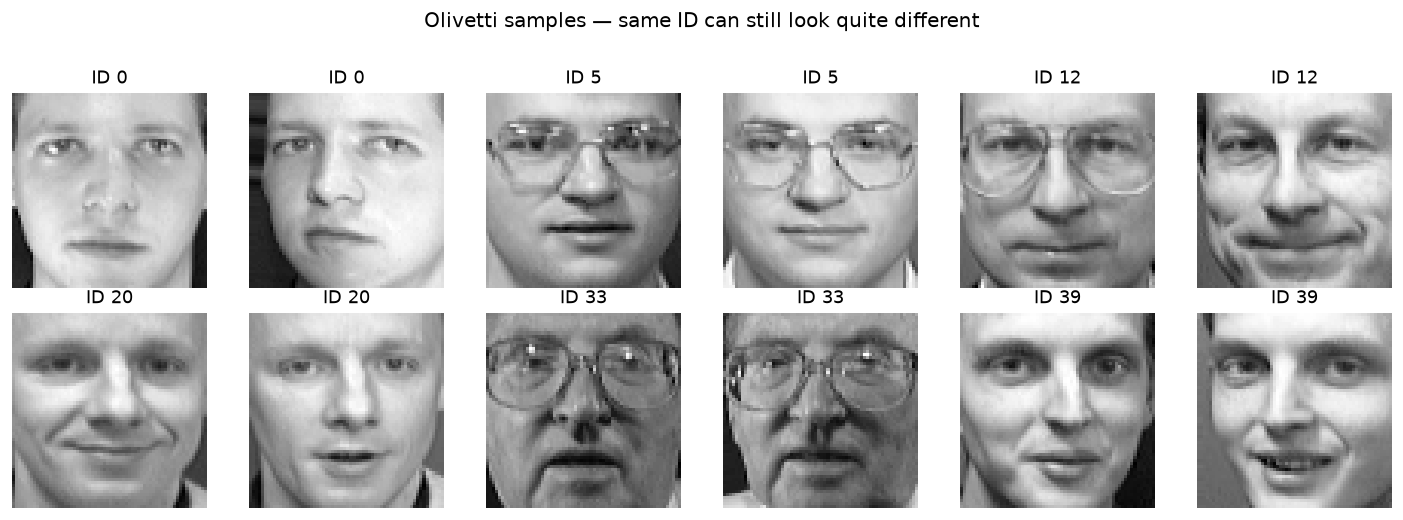

In [2]:
dataset = fetch_olivetti_faces(data_home=str(DATA_HOME), shuffle=False, download_if_missing=True)

X = dataset.data.astype(np.float64)   # (400, 4096)
y = dataset.target.astype(np.int64)   # (400,)

print("X shape:", X.shape, "  (400 faces × 4096 pixels)")
print("y shape:", y.shape)
print("unique people:", len(np.unique(y)))
print("pixel range: [{:.3f}, {:.3f}]".format(X.min(), X.max()))

# Show a few people (2 shots each) so we see pose / expression variation
fig, axes = plt.subplots(2, 6, figsize=(12, 4.2))
axes = axes.flatten()
show_ids = [0, 0, 5, 5, 12, 12, 20, 20, 33, 33, 39, 39]
for ax, person, slot in zip(axes, show_ids, range(12)):
    # first or second image of that person block
    local = 0 if slot % 2 == 0 else 3
    idx = person * 10 + local
    ax.imshow(X[idx].reshape(64, 64), cmap="gray")
    ax.set_title(f"ID {person}")
    ax.axis("off")
plt.suptitle("Olivetti samples — same ID can still look quite different", y=1.02)
plt.tight_layout()
plt.show()

## 2. Per-person train / test split (before any learning)

For every identity we randomly keep **8** images for training and **2** for testing. We do this **before** computing the mean or any eigenface, so test pixels never leak into the model.

Success: split is 8 train / 2 test per person.
X_train: (320, 4096) X_test: (80, 4096)

Displaying 10 random images from the full dataset...


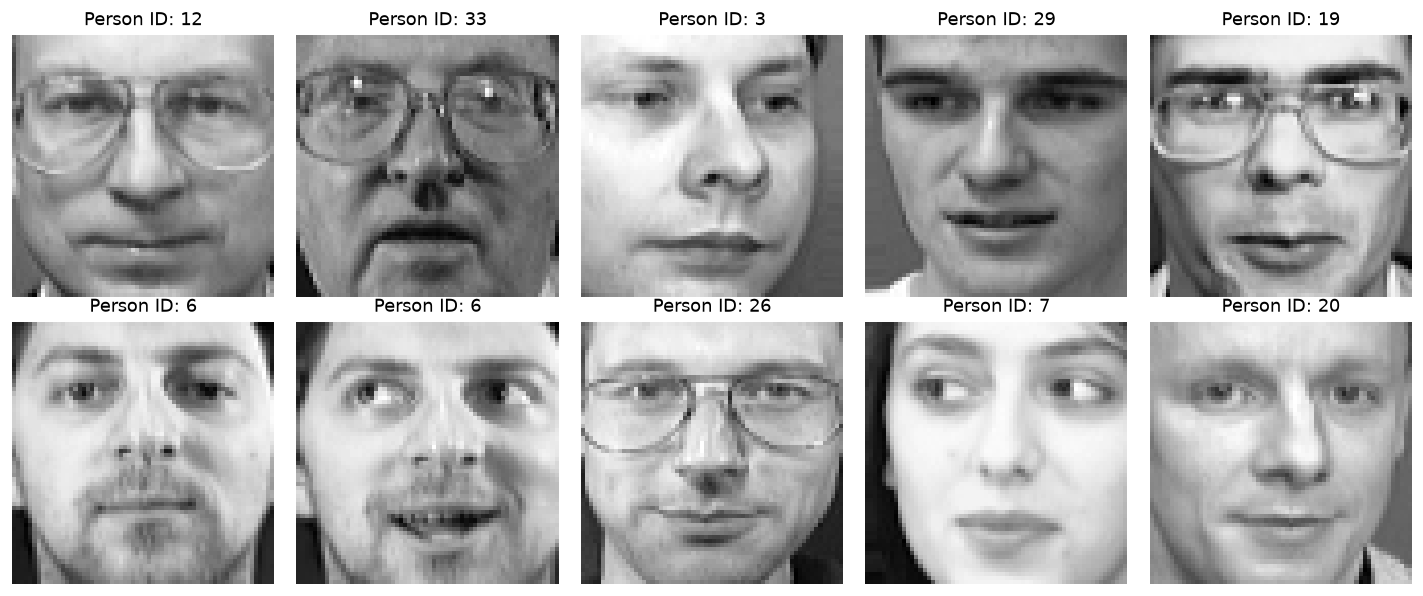

In [3]:
x_train, y_train, x_test, y_test = [], [], [], []

for i in range(40):
    indices = np.arange(10)
    np.random.shuffle(indices)
    for j in range(8):
        idx = i * 10 + indices[j]
        x_train.append(X[idx])
        y_train.append(y[idx])
    for j in range(8, 10):
        idx = i * 10 + indices[j]
        x_test.append(X[idx])
        y_test.append(y[idx])

X_train = np.array(x_train)
y_train = np.array(y_train)
X_test = np.array(x_test)
y_test = np.array(y_test)

error_found = False
for person in range(40):
    if np.sum(y_train == person) != 8 or np.sum(y_test == person) != 2:
        error_found = True
        break

if not error_found:
    print("Success: split is 8 train / 2 test per person.")
    print("X_train:", X_train.shape, "X_test:", X_test.shape)
else:
    print("Error: split ratio incorrect!")

assert X_train.shape == (320, 4096) and X_test.shape == (80, 4096)

# Random preview from the full set
print("\nDisplaying 10 random images from the full dataset...")
random_indices = np.random.choice(len(X), 10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flatten()
for ax, idx in zip(axes, random_indices):
    ax.imshow(X[idx].reshape(64, 64), cmap="gray")
    ax.set_title(f"Person ID: {y[idx]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Mean face and centering (train only)

**Mean face** μ = average of all **training** face vectors.

**Centered face** = original face − μ.

$$
\mu = \frac{1}{n_{\mathrm{train}}}\sum_i x_i, \qquad \tilde{x}=x-\mu
$$

We subtract the **training** mean from both train and test. That is the only honest mean we are allowed to use at test time.


max |train centered mean|: 2.400857290751901e-16


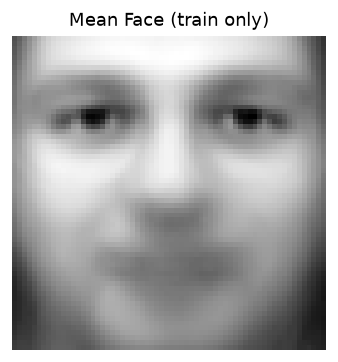

In [4]:
mean_face = np.mean(X_train, axis=0)

X_train_c = X_train - mean_face
X_test_c = X_test - mean_face

# Keep original names used below for centered matrices
X_train = X_train_c
X_test = X_test_c

print("max |train centered mean|:", np.max(np.abs(X_train.mean(axis=0))))
assert np.allclose(X_train.mean(axis=0), 0.0, atol=1e-10)

plt.figure(figsize=(3.4, 3.4))
plt.imshow(mean_face.reshape(64, 64), cmap="gray")
plt.title("Mean Face (train only)")
plt.axis("off")
plt.show()

## 4. PCA via the sample Gram matrix

Each face is $d=4096$ pixels; we have $n=320$ training faces. The full pixel-space covariance would be $4096\times 4096$ — huge. We instead eigendecompose the much smaller **sample Gram matrix** ($320\times 320$):

$$
G=\frac{1}{n-1}XX^\top \in \mathbb{R}^{n\times n}
$$

**How we get eigenfaces from $G$:**
1. Solve $G v = \lambda v$ (small eigenproblem).
2. Map back to pixel space: $u \propto X^\top v$.
3. That $u$ is an eigenvector of the sample covariance of the faces, with the **same** eigenvalue $\lambda$.

**Why divide by $n-1$?**  
So each $\lambda_i$ equals the **sample variance** of the projected coefficient $z_i$.  
Then a morph step of size $\alpha\sqrt{\lambda_i}$ is a true $\pm\alpha$ standard-deviation move — critical for our interpretation experiments later.


In [5]:
n_samples = X_train.shape[0]
gram_matrix = np.dot(X_train, X_train.T) / (n_samples - 1)

eigenvalues, small_eigenvectors = np.linalg.eigh(gram_matrix)

sorted_idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sorted_idx]
small_eigenvectors = small_eigenvectors[:, sorted_idx]

# Map back to 4096-D pixel space
eigenvectors = np.dot(X_train.T, small_eigenvectors)

print("Gram matrix shape:", gram_matrix.shape)
print("Top 5 eigenvalues:", eigenvalues[:5])

Gram matrix shape: (320, 320)
Top 5 eigenvalues: [18.76009004 10.34611263  6.59330225  3.9976178   2.90902753]


## 5. Clean up the eigenfaces

After centering, some eigenvalues are basically zero (numerical junk). We throw those away.

We also scale each kept eigenface to length 1. That way each score is a clean projection onto that direction.


In [6]:
max_eigenvalue = np.max(eigenvalues)
norms = np.linalg.norm(eigenvectors, axis=0)
threshold = max_eigenvalue * 1e-6
valid_mask = eigenvalues > threshold

safe_eigenvectors = np.zeros_like(eigenvectors)
safe_eigenvectors[:, valid_mask] = eigenvectors[:, valid_mask] / norms[valid_mask]
eigenvectors = safe_eigenvectors
eigenvalues = eigenvalues.copy()
# zero-out invalid eigenvalues for clarity
eigenvalues = np.where(valid_mask, eigenvalues, 0.0)
n_keep = int(np.sum(valid_mask))
eigenvectors = eigenvectors[:, :n_keep]
eigenvalues = eigenvalues[:n_keep]

print("Final eigenvectors shape:", eigenvectors.shape)
print("Retained components:", n_keep)

# Orthogonality / unit-norm check on first 40
U40 = eigenvectors[:, :40]
print("max |norm-1|:", np.max(np.abs(np.linalg.norm(U40, axis=0) - 1)))
print("max off-diag |UᵀU|:", np.max(np.abs(U40.T @ U40 - np.eye(40))))

Final eigenvectors shape: (4096, 319)
Retained components: 319
max |norm-1|: 3.3306690738754696e-15
max off-diag |UᵀU|: 5.551115123125783e-15


## 6. Mean face + first 12 eigenfaces

Below: the average face, then the first twelve eigenfaces. Even before measuring, early ones often look like broad light/shade patterns; later ones already look more speckled. Part II checks whether that first impression is real.


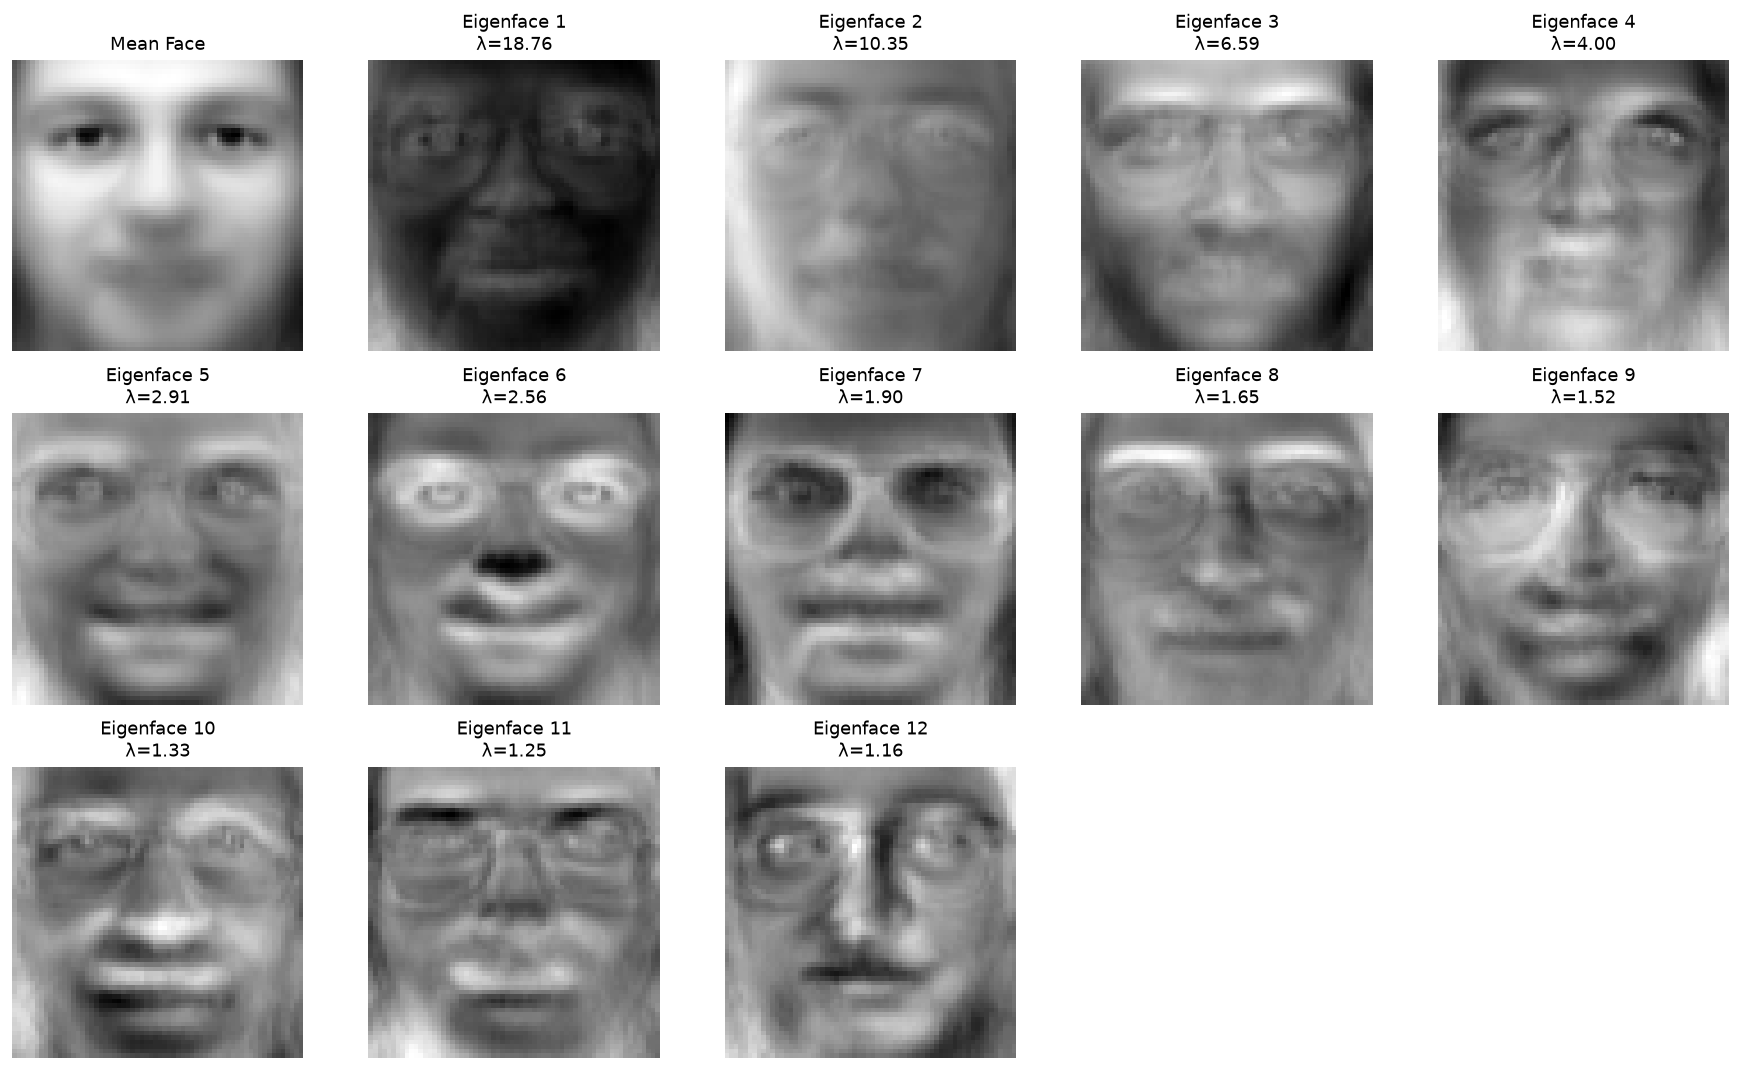

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
axes = axes.flatten()

axes[0].imshow(mean_face.reshape(64, 64), cmap="gray")
axes[0].set_title("Mean Face")
axes[0].axis("off")

# Symmetric scaling helps signed eigenfaces
for i in range(12):
    ef = eigenvectors[:, i].reshape(64, 64)
    v = np.max(np.abs(ef)) + 1e-12
    axes[i + 1].imshow(ef, cmap="gray", vmin=-v, vmax=v)
    axes[i + 1].set_title(f"Eigenface {i + 1}\nλ={eigenvalues[i]:.2f}")
    axes[i + 1].axis("off")

for j in range(13, 15):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## 7. Reconstructing faces at different $k$

For a centered face $\tilde{x}$ and the first $k$ eigenfaces stacked as $U_k$:

- **Project** (get $k$ numbers): $z = U_k^\top \tilde{x}$
- **Reconstruct** (back to image space): $\hat{x} = \mu + U_k z$

$$
z = U_k^\top \tilde{x}, \qquad \hat{x}=\mu + U_k z
$$

We reconstruct several test faces with $k \in \{10, 50, 150, 319\}$. More components should restore finer detail.


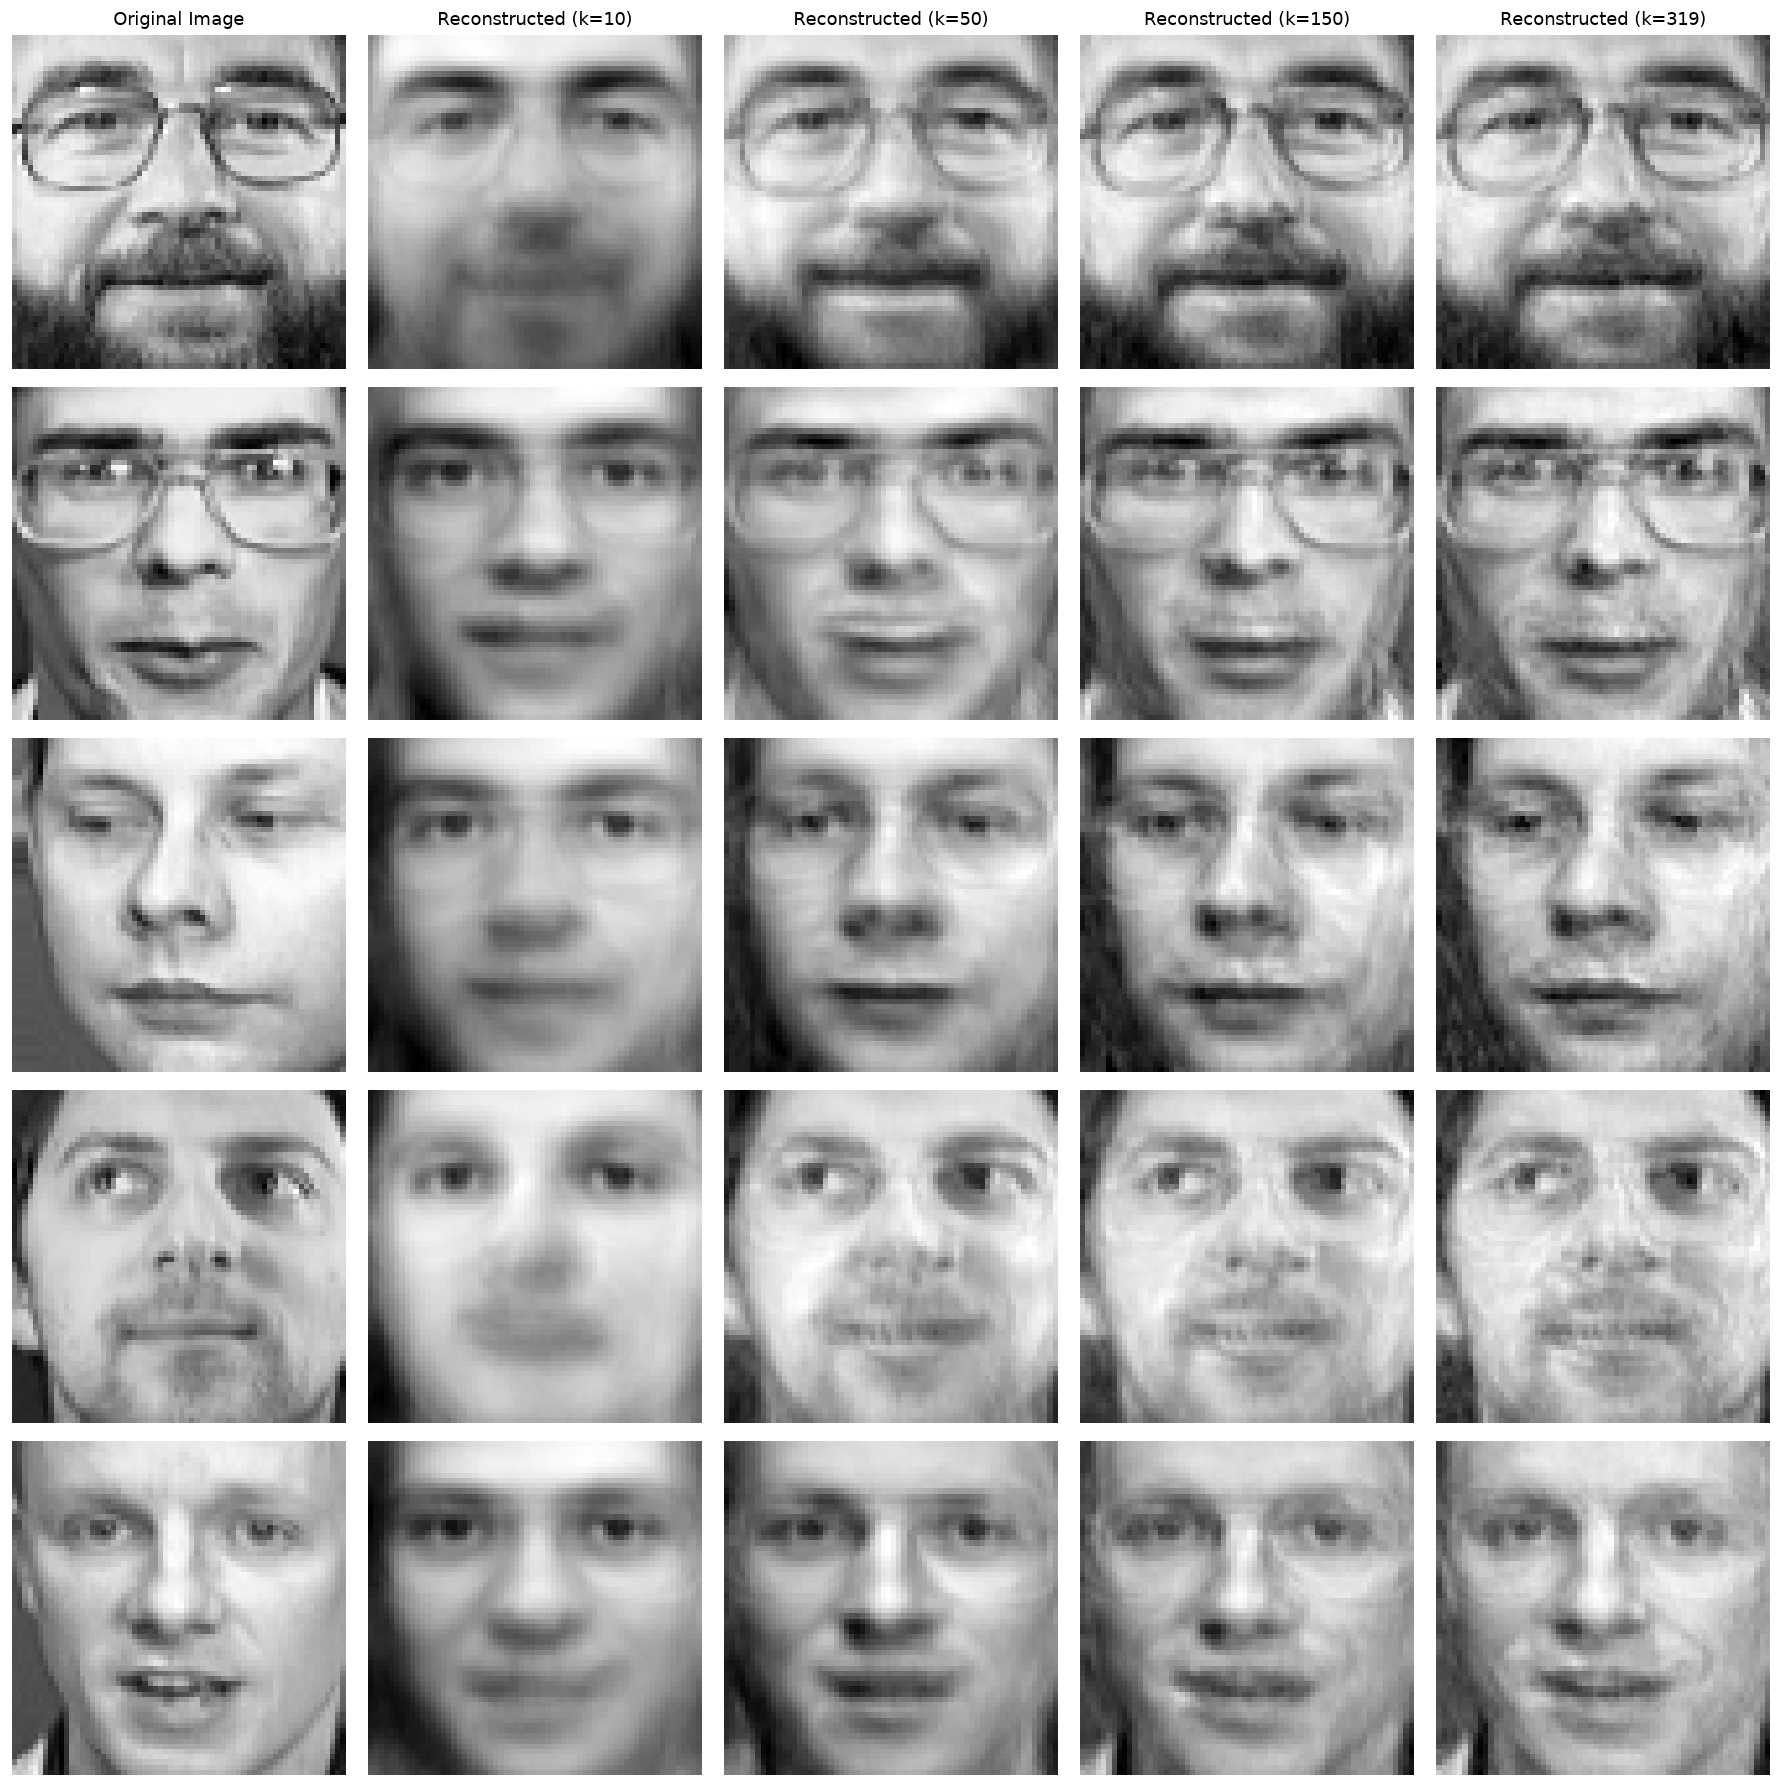

In [8]:
num_images = 5
random_indices = np.random.choice(X_test.shape[0], num_images, replace=False)
k_values = [10, 50, 150, min(319, eigenvectors.shape[1])]

fig, axes = plt.subplots(num_images, len(k_values) + 1, figsize=(15, 3 * num_images))

for row_idx, idx in enumerate(random_indices):
    test_image = X_test[idx]
    original_face = test_image + mean_face
    axes[row_idx, 0].imshow(original_face.reshape(64, 64), cmap="gray")
    axes[row_idx, 0].axis("off")
    if row_idx == 0:
        axes[row_idx, 0].set_title("Original Image")

    for col_idx, k in enumerate(k_values):
        U_k = eigenvectors[:, :k]
        weights = np.dot(test_image, U_k)
        reconstructed_image = mean_face + np.dot(weights, U_k.T)
        axes[row_idx, col_idx + 1].imshow(reconstructed_image.reshape(64, 64), cmap="gray")
        axes[row_idx, col_idx + 1].axis("off")
        if row_idx == 0:
            axes[row_idx, col_idx + 1].set_title(f"Reconstructed (k={k})")

plt.tight_layout()
plt.show()

## 8. Reconstruction error vs $k$

PCA is built to minimize average squared error in a linear model, so test error should fall (or flatten) as we keep more components — it should not systematically get worse.


MSE @ k=10,50,150: ['0.006848', '0.003337', '0.002115']


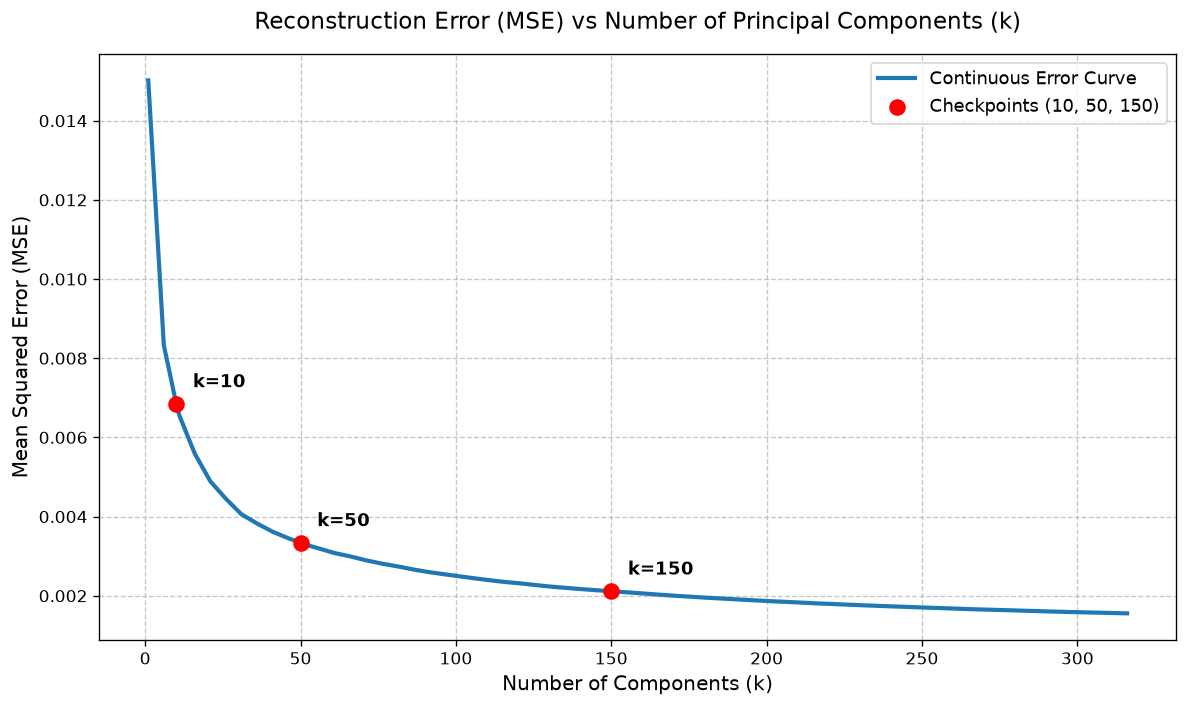

In [9]:
max_k = eigenvectors.shape[1]
k_values_dense = list(range(1, max_k, 5))
for rk in [10, 50, 150]:
    if rk not in k_values_dense and rk <= max_k:
        k_values_dense.append(rk)
k_values_dense.sort()

mse_values = []
prev = np.inf
for k in k_values_dense:
    U_k = eigenvectors[:, :k]
    test_weights = np.dot(X_test, U_k)
    X_test_reconstructed = np.dot(test_weights, U_k.T)
    mse = np.mean((X_test - X_test_reconstructed) ** 2)
    assert mse <= prev + 1e-10
    prev = mse
    mse_values.append(mse)

plt.figure(figsize=(10, 6))
plt.plot(k_values_dense, mse_values, linestyle="-", color="#1f77b4", linewidth=2.5, label="Continuous Error Curve")
required_ks = [10, 50, 150]
highlight_mses = [mse_values[k_values_dense.index(rk)] for rk in required_ks]
plt.scatter(required_ks, highlight_mses, color="red", s=80, zorder=5, label="Checkpoints (10, 50, 150)")
for rk, rmse in zip(required_ks, highlight_mses):
    plt.annotate(f"k={rk}", (rk, rmse), textcoords="offset points", xytext=(10, 10), fontsize=11, fontweight="bold")
plt.title("Reconstruction Error (MSE) vs Number of Principal Components (k)", fontsize=14, pad=15)
plt.xlabel("Number of Components (k)", fontsize=12)
plt.ylabel("Mean Squared Error (MSE)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

print("MSE @ k=10,50,150:", [f"{m:.6f}" for m in highlight_mses])

## 9. A quick identity check (not our main question)

Face PCA is often used for recognition, so we run a nearest-neighbor check to make sure our face space works. Our real interest is still **what each component changes**, not chasing the perfect accuracy score.

### Two models we compare
We sweep many values of $k$ and compare:

1. **Model A — Keep PC1 + Euclidean (L2)**  
   Use components $1\ldots k$. Distance = ordinary straight-line distance in score space (gaps are squared).

2. **Model B — Skip PC1 + Manhattan (L1)**  
   Use components $2\ldots(k+1)$ (same number of components, but drop PC1). Distance = sum of absolute score gaps.

### Why these two?
- Model A is the “plain” PCA matcher: keep the strongest component, use standard Euclidean distance.
- Model B is the classic practical trick from eigenface matching: PC1 often carries a lot of overall shade, and L1 is gentler than L2 when one axis has a large gap. Squaring in L2 can over-punish that.

We keep everything else the same, so the comparison is fair: **same $k$**, only the PC1 choice and the distance change.


Nearest-neighbor identity: two models across k
Model A = Keep PC1 + Euclidean (L2)   → use PC1..k
Model B = Skip PC1 + Manhattan (L1)   → use PC2..(k+1)
   k     A keep+L2     B skip+L1     Δ (B − A)
  10        87.50%        78.75%        -8.75%
  50        91.25%        92.50%        +1.25%
 150        92.50%        95.00%        +2.50%

Best on this split:
  Model A (Keep PC1 + L2): best 92.50% at k=61
  Model B (Skip PC1 + L1): best 96.25% at k=121
  Mean over all tested k:  A=90.90%   B=92.22%
Across 72 values of k: B better 48, A better 11, ties 13
Winner (by mean accuracy over k): Model B — Skip PC1 + Manhattan
Peak-best single setting: Model B at k=121 (96.25%)


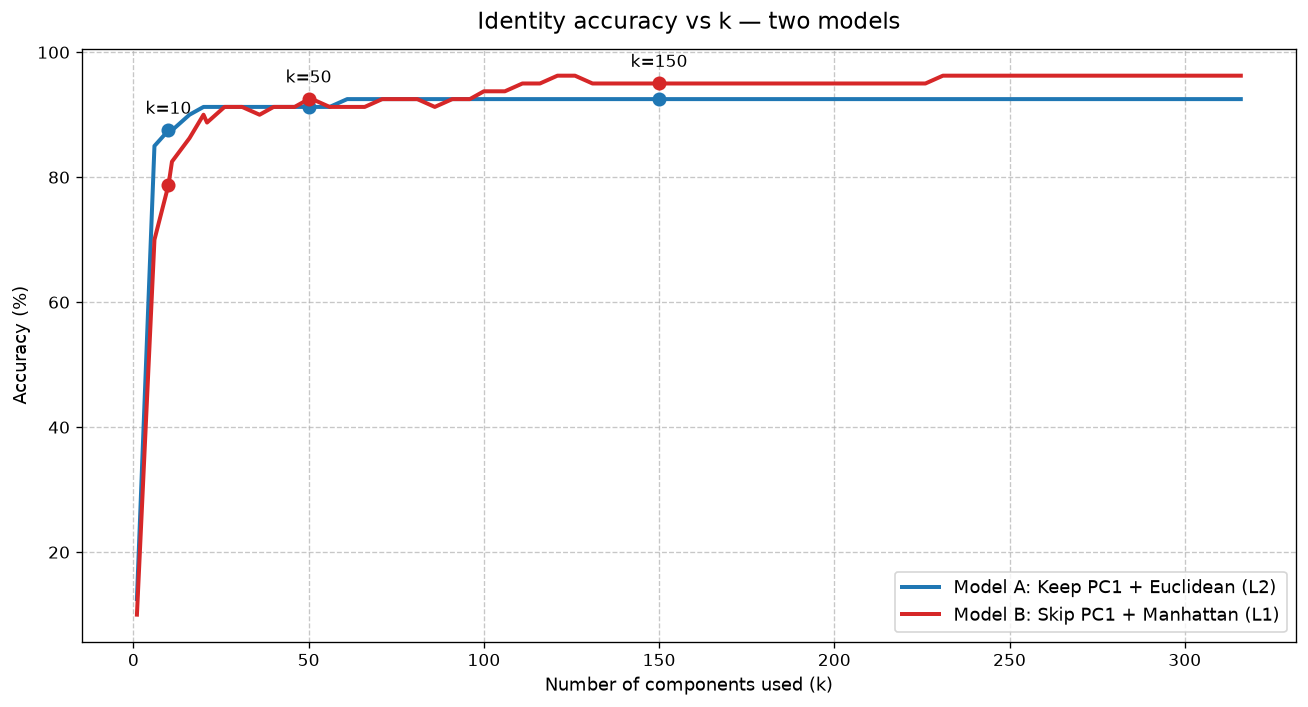

In [10]:
def nn_accuracy(U, metric="l2"):
    """Nearest-neighbor identity accuracy on projected scores."""
    train_w = X_train @ U
    test_w = X_test @ U
    correct = 0
    for i in range(len(test_w)):
        if metric == "l2":
            distances = np.linalg.norm(train_w - test_w[i], axis=1)
        elif metric == "l1":
            distances = np.sum(np.abs(train_w - test_w[i]), axis=1)
        else:
            raise ValueError(metric)
        if y_train[np.argmin(distances)] == y_test[i]:
            correct += 1
    return 100.0 * correct / len(test_w)

max_k = eigenvectors.shape[1]
k_values = list(range(1, max_k, 5))
for rk in [10, 20, 30, 40, 50, 80, 100, 150]:
    if rk not in k_values and rk <= max_k - 1:
        k_values.append(rk)
k_values = sorted(k for k in k_values if 1 <= k <= max_k - 1)

acc_A = []  # Keep PC1 + Euclidean
acc_B = []  # Skip PC1 + L1

print("Nearest-neighbor identity: two models across k")
print("Model A = Keep PC1 + Euclidean (L2)   → use PC1..k")
print("Model B = Skip PC1 + Manhattan (L1)   → use PC2..(k+1)")
print(f"{'k':>4}  {'A keep+L2':>12}  {'B skip+L1':>12}  {'Δ (B − A)':>12}")

for k in k_values:
    U_A = eigenvectors[:, :k]
    U_B = eigenvectors[:, 1:1 + k]
    a = nn_accuracy(U_A, metric="l2")
    b = nn_accuracy(U_B, metric="l1")
    acc_A.append(a)
    acc_B.append(b)

for rk in [10, 50, 150]:
    if rk in k_values:
        i = k_values.index(rk)
        print(f"{rk:>4}  {acc_A[i]:>11.2f}%  {acc_B[i]:>11.2f}%  {acc_B[i]-acc_A[i]:>+11.2f}%")

best_A_i = int(np.argmax(acc_A))
best_B_i = int(np.argmax(acc_B))
mean_A = float(np.mean(acc_A))
mean_B = float(np.mean(acc_B))

print("\nBest on this split:")
print(f"  Model A (Keep PC1 + L2): best {acc_A[best_A_i]:.2f}% at k={k_values[best_A_i]}")
print(f"  Model B (Skip PC1 + L1): best {acc_B[best_B_i]:.2f}% at k={k_values[best_B_i]}")
print(f"  Mean over all tested k:  A={mean_A:.2f}%   B={mean_B:.2f}%")

n_B_better = int(np.sum(np.array(acc_B) > np.array(acc_A)))
n_A_better = int(np.sum(np.array(acc_A) > np.array(acc_B)))
n_tie = len(k_values) - n_B_better - n_A_better
print(f"Across {len(k_values)} values of k: B better {n_B_better}, A better {n_A_better}, ties {n_tie}")

if mean_B > mean_A + 1e-9:
    id_winner = "skip_pc1_l1"
    id_winner_name = "Skip PC1 + L1"
    print("Winner (by mean accuracy over k): Model B — Skip PC1 + Manhattan")
elif mean_A > mean_B + 1e-9:
    id_winner = "keep_pc1_l2"
    id_winner_name = "Keep PC1 + Euclidean"
    print("Winner (by mean accuracy over k): Model A — Keep PC1 + Euclidean")
else:
    id_winner = "tie"
    id_winner_name = "Tie"
    print("Winner: essentially a TIE on mean accuracy")

# Also report peak-best model
if acc_B[best_B_i] > acc_A[best_A_i] + 1e-9:
    print(f"Peak-best single setting: Model B at k={k_values[best_B_i]} ({acc_B[best_B_i]:.2f}%)")
elif acc_A[best_A_i] > acc_B[best_B_i] + 1e-9:
    print(f"Peak-best single setting: Model A at k={k_values[best_A_i]} ({acc_A[best_A_i]:.2f}%)")
else:
    print("Peak-best: both models reach the same top accuracy")

plt.figure(figsize=(11, 6))
plt.plot(k_values, acc_A, "-", lw=2.4, color="#1f77b4",
         label="Model A: Keep PC1 + Euclidean (L2)")
plt.plot(k_values, acc_B, "-", lw=2.4, color="#d62728",
         label="Model B: Skip PC1 + Manhattan (L1)")
for rk in [10, 50, 150]:
    if rk in k_values:
        i = k_values.index(rk)
        plt.scatter([rk], [acc_A[i]], color="#1f77b4", s=55, zorder=5)
        plt.scatter([rk], [acc_B[i]], color="#d62728", s=55, zorder=5)
        plt.annotate(f"k={rk}", (rk, max(acc_A[i], acc_B[i])),
                     textcoords="offset points", xytext=(0, 10), ha="center", fontsize=10)
plt.title("Identity accuracy vs k — two models", fontsize=14, pad=12)
plt.xlabel("Number of components used (k)")
plt.ylabel("Accuracy (%)")
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

identity_checkpoints = {
    rk: {"A_keep_L2": acc_A[k_values.index(rk)], "B_skip_L1": acc_B[k_values.index(rk)]}
    for rk in [10, 50, 150] if rk in k_values
}


## 9b. Failure gallery

We look at mistakes for $k=150$ under the **winning** model from above. This is still not our main question — it only shows that high accuracy is not perfect identity.


Failure Analysis at k = 150  (Skip PC1 + Manhattan)
Mistakes: 4 / 80  (acc=95.00%)


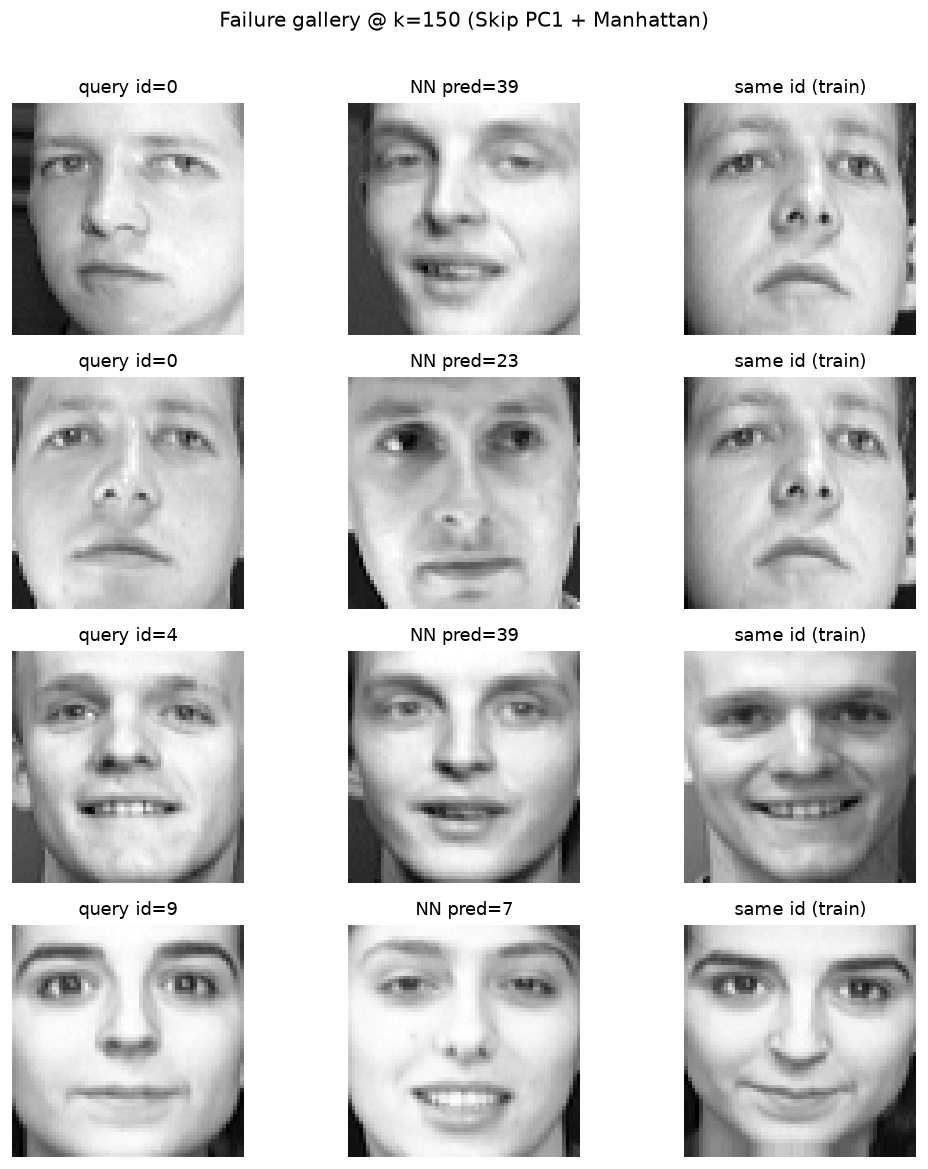

In [11]:
np.random.seed(42)
k_fail = 150

if id_winner == "keep_pc1_l2":
    U_fail = eigenvectors[:, :k_fail]
    metric = "l2"
    fail_label = "Keep PC1 + Euclidean"
else:
    # skip PC1 + L1 (also default on tie)
    U_fail = eigenvectors[:, 1:1 + k_fail]
    metric = "l1"
    fail_label = "Skip PC1 + Manhattan"

Z_tr = X_train @ U_fail
Z_te = X_test @ U_fail

pred = []
for z in Z_te:
    if metric == "l2":
        d = np.linalg.norm(Z_tr - z, axis=1)
    else:
        d = np.sum(np.abs(Z_tr - z), axis=1)
    pred.append(y_train[np.argmin(d)])
pred = np.array(pred)
wrong = np.where(pred != y_test)[0]
print(f"Failure Analysis at k = {k_fail}  ({fail_label})")
print(f"Mistakes: {len(wrong)} / {len(y_test)}  (acc={(1 - len(wrong)/len(y_test))*100:.2f}%)")

show_n = min(6, len(wrong))
if show_n == 0:
    print("No mistakes to display at this k.")
else:
    fig, axes = plt.subplots(show_n, 3, figsize=(9, 2.4 * show_n))
    if show_n == 1:
        axes = np.array([axes])
    for row, idx in enumerate(wrong[:show_n]):
        query = np.clip(X_test[idx] + mean_face, 0, 1).reshape(64, 64)
        z = Z_te[idx]
        if metric == "l2":
            nn = np.argmin(np.linalg.norm(Z_tr - z, axis=1))
        else:
            nn = np.argmin(np.sum(np.abs(Z_tr - z), axis=1))
        neighbor = np.clip(X_train[nn] + mean_face, 0, 1).reshape(64, 64)
        same = np.where(y_train == y_test[idx])[0][0]
        truth = np.clip(X_train[same] + mean_face, 0, 1).reshape(64, 64)
        axes[row, 0].imshow(query, cmap="gray"); axes[row, 0].set_title(f"query id={y_test[idx]}")
        axes[row, 1].imshow(neighbor, cmap="gray"); axes[row, 1].set_title(f"NN pred={pred[idx]}")
        axes[row, 2].imshow(truth, cmap="gray"); axes[row, 2].set_title("same id (train)")
        for ax in axes[row]:
            ax.axis("off")
    plt.suptitle(f"Failure gallery @ k={k_fail} ({fail_label})", y=1.01)
    plt.tight_layout()
    plt.show()


## 10. Cross-check against SVD

Individual eigenfaces can flip sign ($u$ vs $-u$). What should match is the **space they span** and the **reconstructions**. With sample-covariance scaling, the eigenvalues should also line up with the squared singular values (up to $n-1$).


In [12]:
print("Comparing PCA vs SVD")
U, S, Vt = np.linalg.svd(X_train, full_matrices=False)
svd_eigenvectors = Vt.T

k = 10
pca_vectors = eigenvectors[:, :k]
svd_vectors = svd_eigenvectors[:, :k]

print(f"1. Absolute cosine between corresponding vectors (first {k}):")
for i in range(k):
    dot_prod = np.abs(np.dot(pca_vectors[:, i], svd_vectors[:, i]))
    print(f" - Component {i+1:<2}: match = {dot_prod:.6f}")

# Subspace check via principal angles
M = pca_vectors.T @ svd_vectors
sing = np.clip(np.linalg.svd(M, compute_uv=False), -1, 1)
print(f"Max principal angle: {np.degrees(np.arccos(sing.min())):.6e} deg")

print("\n2. Reconstruction MSE at k=10:")
test_weights_pca = np.dot(X_test, pca_vectors)
recon_pca = np.dot(test_weights_pca, pca_vectors.T)
mse_pca = np.mean((X_test - recon_pca) ** 2)

test_weights_svd = np.dot(X_test, svd_vectors)
recon_svd = np.dot(test_weights_svd, svd_vectors.T)
mse_svd = np.mean((X_test - recon_svd) ** 2)
print(f" - PCA MSE : {mse_pca:.6f}")
print(f" - SVD MSE : {mse_svd:.6f}")

lam_svd = (S[:k] ** 2) / (n_samples - 1)
rel = np.max(np.abs(eigenvalues[:k] - lam_svd) / np.maximum(lam_svd, 1e-30))
print(f" - max rel |λ − σ²/(n-1)|: {rel:.3e}")

Comparing PCA vs SVD
1. Absolute cosine between corresponding vectors (first 10):
 - Component 1 : match = 1.000000
 - Component 2 : match = 1.000000
 - Component 3 : match = 1.000000
 - Component 4 : match = 1.000000
 - Component 5 : match = 1.000000
 - Component 6 : match = 1.000000
 - Component 7 : match = 1.000000
 - Component 8 : match = 1.000000
 - Component 9 : match = 1.000000
 - Component 10: match = 1.000000
Max principal angle: 2.561321e-06 deg

2. Reconstruction MSE at k=10:
 - PCA MSE : 0.006848
 - SVD MSE : 0.006848
 - max rel |λ − σ²/(n-1)|: 1.559e-15


# Part II — Interpreting the principal components

This is the part we care about most. We want to *feel* what each component does to a face, then check that feeling with numbers.

We do it in layers:

1. make sure $\lambda$ really is the variance of the scores — so our $\pm$ steps are honest,
2. change **one** component at a time and watch the face,
3. measure simple things (brightness, left/right shade, how speckled the eigenface looks),
4. compare early components with late ones using the **same** step size,
5. try rebuilding a face **without** the first few components, to see what those early ones were carrying.

We keep the language humble. If PC1 mostly brightens or darkens the whole face, we say that. We do not force a prettier story than the pictures support.


## 11. Make sure $\lambda_i$ is really the variance of $z_i$

For a unit-length eigenface $u_i$, each training face gets a score

$$
z_i^{(j)} = x_j^\top u_i
$$

If we built PCA with sample covariance, $\lambda_i$ should equal how much those scores vary.

We check that here. When it holds, $\sqrt{\lambda_i}$ is exactly **one standard deviation** of $z_i$. That sounds dry, but it matters: later, when we move $\pm 2$ standard deviations along a component, we know the step size is meaningful — not an arbitrary zoom.


max relative |Var(z_i) − λ_i|: 2.011e-14
Confirmed: each λ_i is the sample variance of coefficient z_i.
Therefore √λ_i is exactly 1 std of that coefficient.


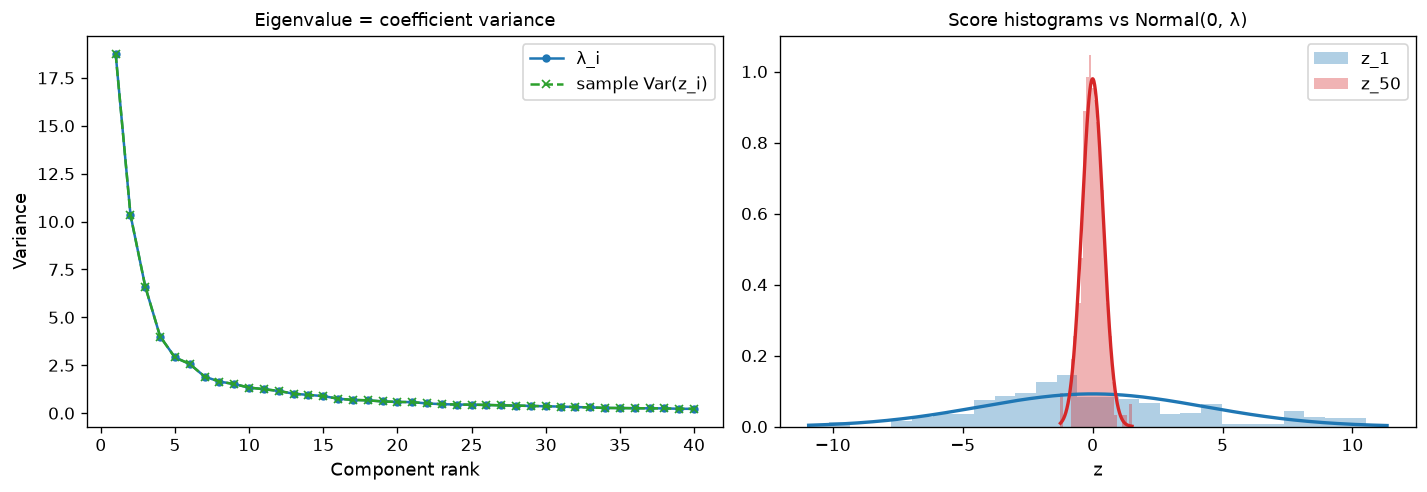

In [13]:
# All training scores: (n_samples, n_components)
Z_all = X_train @ eigenvectors
emp_var = np.var(Z_all, axis=0, ddof=1)
rel_err = np.max(np.abs(emp_var - eigenvalues) / np.maximum(eigenvalues, 1e-30))
print(f"max relative |Var(z_i) − λ_i|: {rel_err:.3e}")
assert rel_err < 1e-6
print("Confirmed: each λ_i is the sample variance of coefficient z_i.")
print("Therefore √λ_i is exactly 1 std of that coefficient.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
m = 40
axes[0].plot(np.arange(1, m + 1), eigenvalues[:m], "o-", ms=4, label="λ_i", color="#1f77b4")
axes[0].plot(np.arange(1, m + 1), emp_var[:m], "x--", ms=5, label="sample Var(z_i)", color="#2ca02c")
axes[0].set_xlabel("Component rank")
axes[0].set_ylabel("Variance")
axes[0].set_title("Eigenvalue = coefficient variance")
axes[0].legend()

for rank, color in [(1, "#1f77b4"), (50, "#d62728")]:
    z = Z_all[:, rank - 1]
    axes[1].hist(z, bins=28, density=True, alpha=0.35, label=f"z_{rank}", color=color)
    xs = np.linspace(z.min(), z.max(), 200)
    pdf = np.exp(-0.5 * xs**2 / eigenvalues[rank - 1]) / np.sqrt(2 * np.pi * eigenvalues[rank - 1])
    axes[1].plot(xs, pdf, color=color, lw=2)
axes[1].set_title("Score histograms vs Normal(0, λ)")
axes[1].set_xlabel("z")
axes[1].legend()
plt.tight_layout()
plt.show()

## 12. Morph strips — changing one component at a time

We build faces by changing **only one** principal component:

$$
x(\alpha)=\mu+\alpha\sqrt{\lambda_i}\,u_i, \qquad \alpha\in\{-3,-2,-1,0,1,2,3\}
$$

In plain words: start from the mean face, then move $\alpha$ standard deviations along eigenface $u_i$.

Nothing else is allowed to change. That is what makes this honest. If the face mostly gets brighter or darker, that component is mostly about light. If one side brightens and the other darkens, it is more about side shade. If only tiny speckles change, we are looking at a late, fine component.

We do this for early, middle, and late components so the difference is visible, not just claimed.


PC 1: λ=18.760, √λ=4.331, range@±3σ ≈ (0.20247900758088067, 0.9963443725438363) … (0.11936816274027932, 0.628323103908258), clip_needed=0/7
PC 2: λ=10.346, √λ=3.217, range@±3σ ≈ (0.07046637564034469, 0.7787697720929878) … (0.044248236908403626, 0.98496283632196), clip_needed=0/7
PC 3: λ=6.593, √λ=2.568, range@±3σ ≈ (0.19342340704997815, 0.7509005520354057) … (0.06419248329092209, 0.9281929432581641), clip_needed=0/7
PC 4: λ=3.998, √λ=1.999, range@±3σ ≈ (0.047894179720530894, 0.8479012922241718) … (0.18657667764546382, 0.8068605050610742), clip_needed=0/7
PC 5: λ=2.909, √λ=1.706, range@±3σ ≈ (0.07402683335762772, 0.7618435910473509) … (0.22895987017055672, 0.8055063672065251), clip_needed=0/7
PC 10: λ=1.334, √λ=1.155, range@±3σ ≈ (0.18283765534912563, 0.8313930711542321) … (0.23582362792077033, 0.7369370393410798), clip_needed=0/7
PC 20: λ=0.585, √λ=0.765, range@±3σ ≈ (0.17532883358170828, 0.7947936739338446) … (0.19635089462861524, 0.7570656837656293), clip_needed=0/7
PC 50: λ=0.166, √

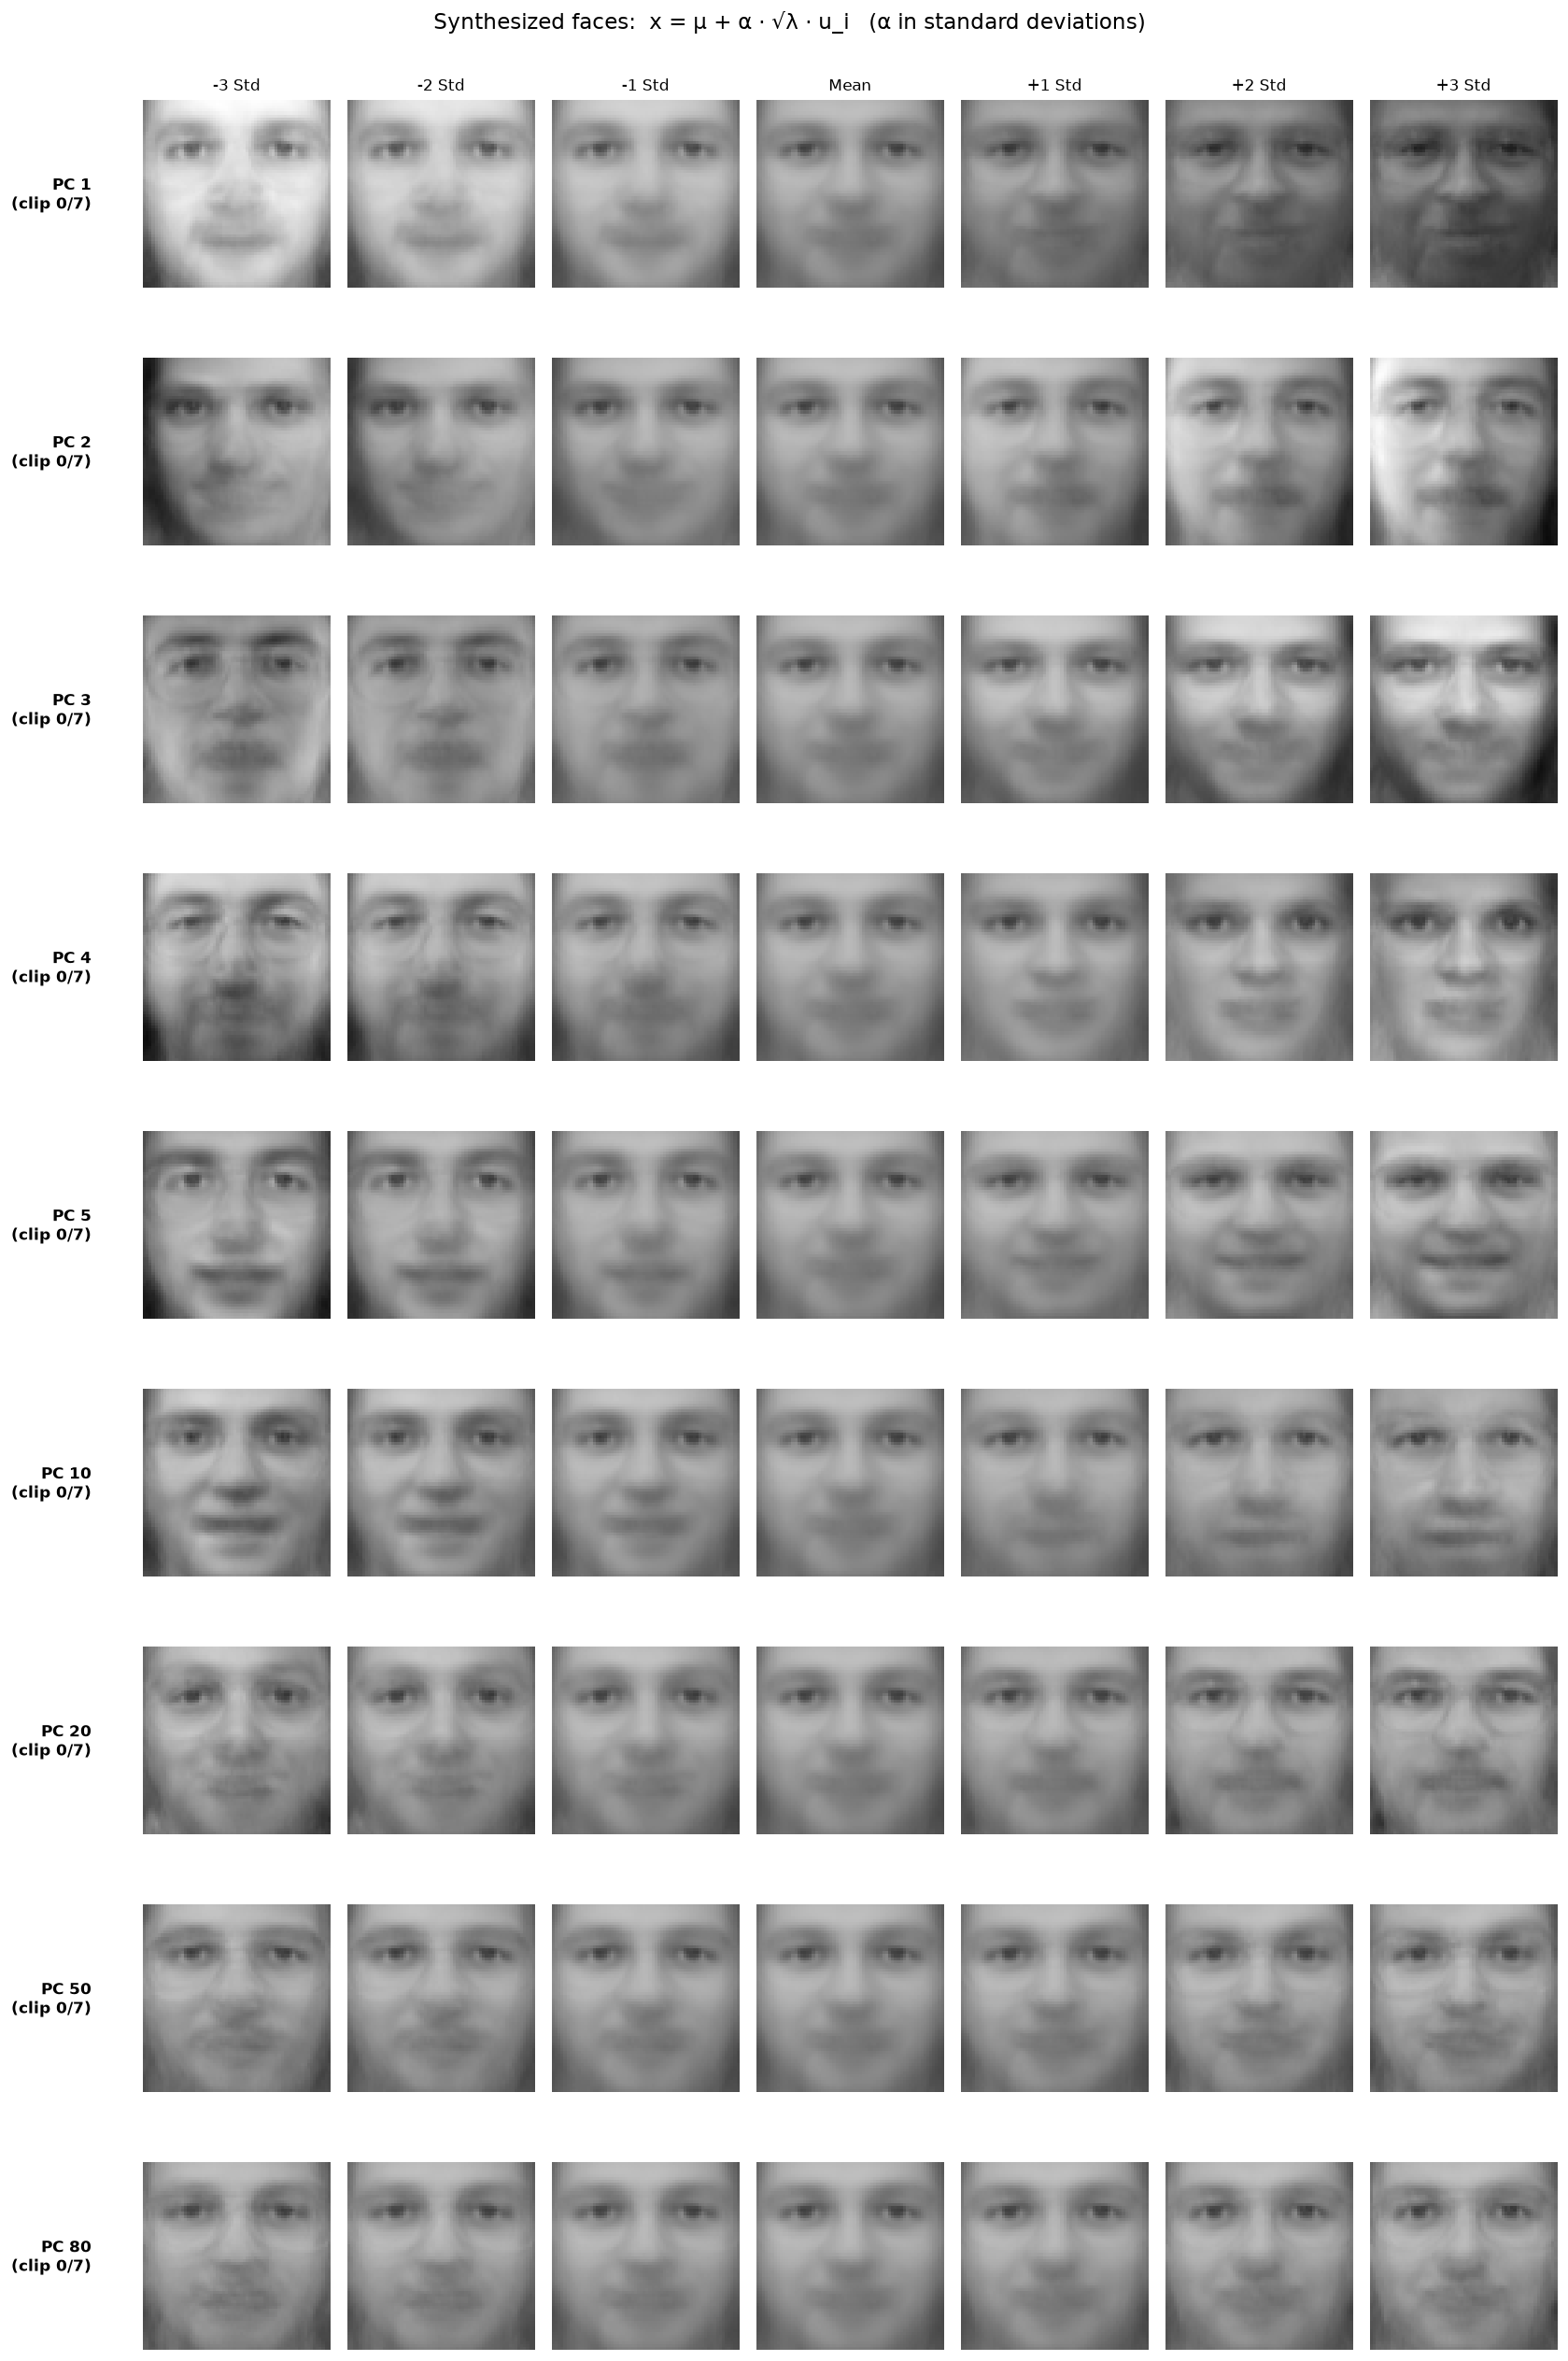

In [14]:
def morph_strip(pc_index, multipliers=(-3, -2, -1, 0, 1, 2, 3)):
    '''Return list of synthesized faces for one PC (already in [display] form).'''
    u_i = eigenvectors[:, pc_index]
    std_dev = np.sqrt(eigenvalues[pc_index])
    faces, ranges = [], []
    for c in multipliers:
        face = mean_face + c * std_dev * u_i
        ranges.append((float(face.min()), float(face.max())))
        faces.append(np.clip(face, 0.0, 1.0))
    return faces, ranges

target_pcs = [0, 1, 2, 3, 4, 9, 19, 49, 79]  # 1-based: 1,2,3,4,5,10,20,50,80
multipliers = [-3, -2, -1, 0, 1, 2, 3]

fig, axes = plt.subplots(len(target_pcs), len(multipliers), figsize=(14, 2.35 * len(target_pcs)))
for idx, pc_index in enumerate(target_pcs):
    faces, ranges = morph_strip(pc_index, multipliers)
    n_clip = sum(1 for lo, hi in ranges if lo < -0.02 or hi > 1.02)
    for col_idx, (c, face) in enumerate(zip(multipliers, faces)):
        axes[idx, col_idx].imshow(face.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
        if idx == 0:
            axes[idx, col_idx].set_title("Mean" if c == 0 else f"{c:+d} Std", fontsize=10)
        axes[idx, col_idx].axis("off")
    axes[idx, 0].text(-18, 32, f"PC {pc_index + 1}\n(clip {n_clip}/7)", fontsize=10,
                      fontweight="bold", va="center", ha="right")
    print(f"PC {pc_index+1}: λ={eigenvalues[pc_index]:.3f}, √λ={np.sqrt(eigenvalues[pc_index]):.3f}, "
          f"range@±3σ ≈ {ranges[0]} … {ranges[-1]}, clip_needed={n_clip}/7")

plt.tight_layout()
plt.suptitle("Synthesized faces:  x = μ + α · √λ · u_i   (α in standard deviations)", y=1.01, fontsize=14)
plt.show()

## 13. A careful reading of the leading eigenfaces

Looking is necessary, but easy to fool ourselves with. So for each early component we put three things side by side:

1. the eigenface itself,
2. the mean face moved $-2$ and $+2$ standard deviations on that component,
3. a few simple measurements of the training scores $z_i$:
   - how much they move with **overall brightness**,
   - how much they move with **left–right** shade imbalance,
   - how much they move with **top–bottom** shade imbalance,
   - how speckled / sharp the eigenface itself looks.

**A soft warning.** Even a huge brightness link does not mean “this component is lighting and nothing else.” It means lighting is *the main thing*. Faces are messy; components can mix several effects. We describe the strongest pattern we can defend.


Leading-component measurements (training split):
 PC        λ corr(z,bright)  corr(z,L-R)  corr(z,T-B)      HF      Lap
  1   18.760         -0.986        0.252       -0.027   0.003   0.0018
  2   10.346          0.116        0.942        0.132   0.026   0.0032
  3    6.593         -0.030        0.079        0.718   0.014   0.0036
  4    3.998          0.058        0.078       -0.600   0.026   0.0050
  5    2.909          0.080        0.026        0.213   0.014   0.0042
  6    2.564          0.020       -0.009        0.068   0.013   0.0048
  7    1.905         -0.036        0.009       -0.097   0.011   0.0048
  8    1.649          0.007        0.089       -0.033   0.021   0.0059
  9    1.517          0.020        0.093        0.065   0.017   0.0051
 10    1.334          0.015       -0.089       -0.036   0.020   0.0056
 11    1.251          0.012        0.018       -0.073   0.027   0.0068
 12    1.159         -0.003        0.026       -0.038   0.029   0.0064


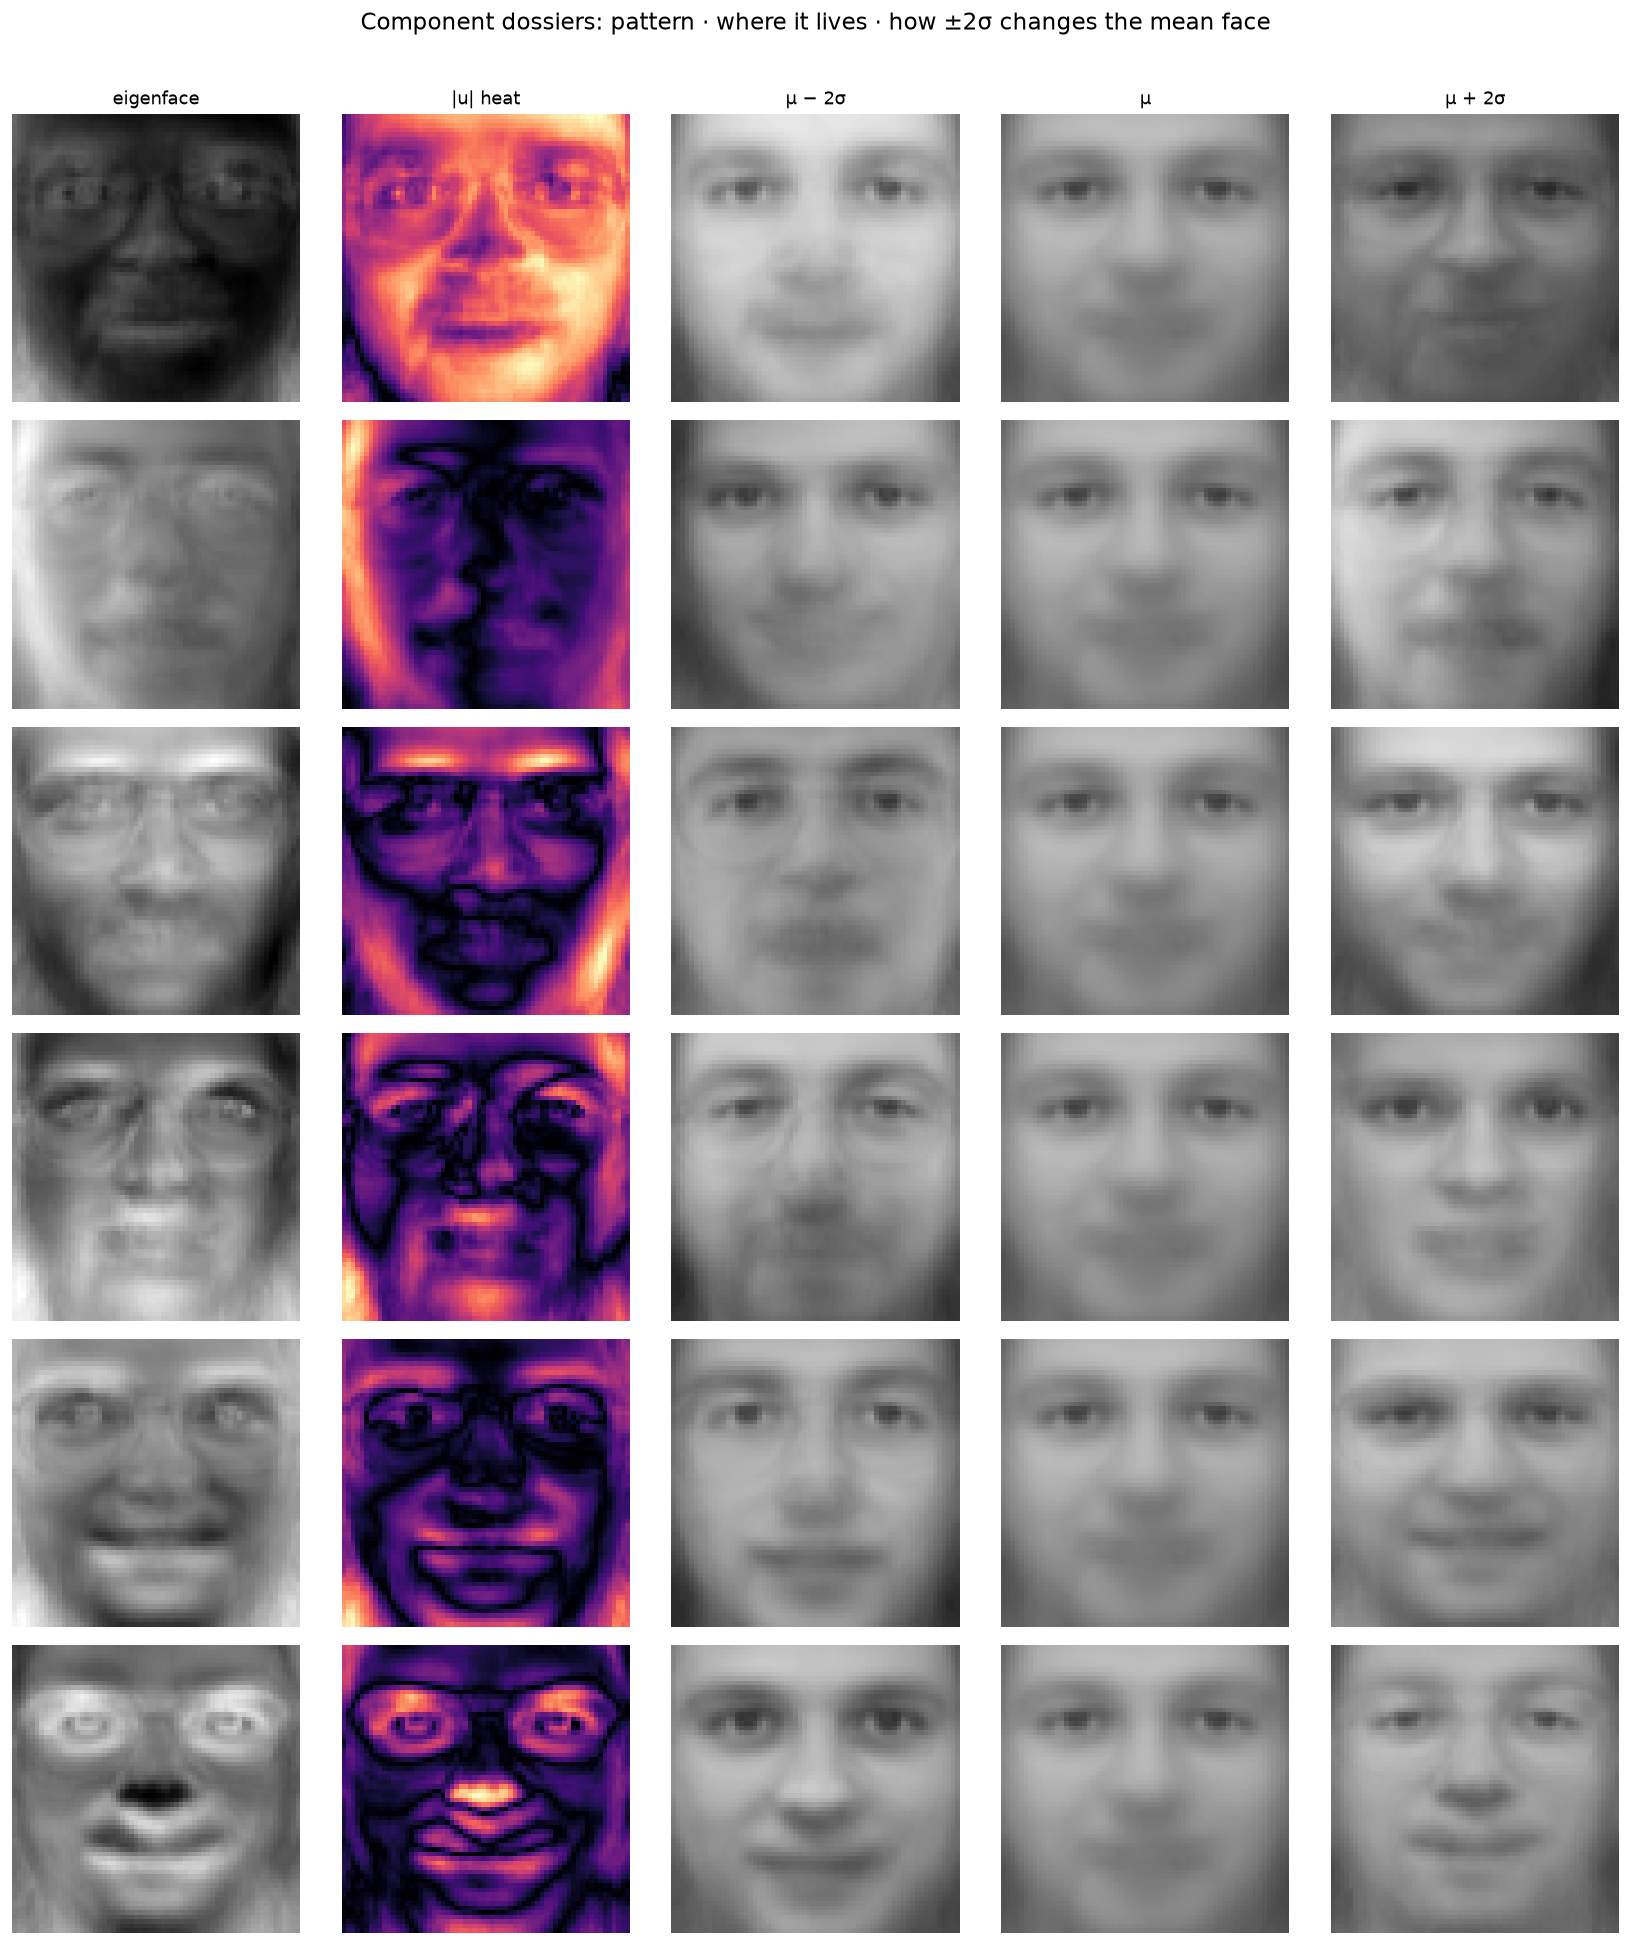

In [15]:
def left_right_asymmetry(flat_face):
    img = flat_face.reshape(64, 64)
    return float(img[:, :32].mean() - img[:, 32:].mean())

def top_bottom_asymmetry(flat_face):
    img = flat_face.reshape(64, 64)
    return float(img[:32, :].mean() - img[32:, :].mean())

def brightness(flat_face):
    return float(flat_face.mean())

def hf_fraction(vec):
    img = vec.reshape(64, 64)
    F = np.fft.fftshift(np.fft.fft2(img))
    power = np.abs(F) ** 2
    yy, xx = np.ogrid[:64, :64]
    r = np.sqrt((yy - 32) ** 2 + (xx - 32) ** 2)
    high = power[r > 16].sum()
    return float(high / power.sum())

def laplacian_energy(vec):
    img = vec.reshape(64, 64)
    lap = (-4 * img + np.roll(img, 1, 0) + np.roll(img, -1, 0)
           + np.roll(img, 1, 1) + np.roll(img, -1, 1))
    return float(np.mean(np.abs(lap)))

# Precompute simple face stats on training set (centered faces)
bright = np.array([brightness(X_train[j]) for j in range(len(X_train))])
lr = np.array([left_right_asymmetry(X_train[j]) for j in range(len(X_train))])
tb = np.array([top_bottom_asymmetry(X_train[j]) for j in range(len(X_train))])

def corr(a, b):
    if np.std(a) < 1e-12 or np.std(b) < 1e-12:
        return 0.0
    return float(np.corrcoef(a, b)[0, 1])

# Literature-informed *hypothesis templates* (we verify against OUR measurements)
lit_notes = {}

analysis_rows = []
for pc in range(12):
    u = eigenvectors[:, pc]
    z = Z_all[:, pc]
    row = {
        "pc": pc + 1,
        "lambda": float(eigenvalues[pc]),
        "corr_brightness": corr(z, bright),
        "corr_LR": corr(z, lr),
        "corr_TB": corr(z, tb),
        "hf": hf_fraction(u),
        "lap": laplacian_energy(u),
        "energy_center": float(np.mean(np.abs(u.reshape(64, 64)[16:48, 16:48]))),
        "energy_border": float(np.mean(np.abs(u.reshape(64, 64))) - 0),  # placeholder refined below
    }
    img_abs = np.abs(u.reshape(64, 64))
    center = img_abs[16:48, 16:48].mean()
    border = img_abs.mean()
    row["center_vs_mean_abs"] = float(center / (border + 1e-12))
    analysis_rows.append(row)

print("Leading-component measurements (training split):")
print(f"{'PC':>3} {'λ':>8} {'corr(z,bright)':>14} {'corr(z,L-R)':>12} {'corr(z,T-B)':>12} {'HF':>7} {'Lap':>8}")
for r in analysis_rows:
    print(f"{r['pc']:3d} {r['lambda']:8.3f} {r['corr_brightness']:14.3f} {r['corr_LR']:12.3f} "
          f"{r['corr_TB']:12.3f} {r['hf']:7.3f} {r['lap']:8.4f}")

# Visual dossier for first 6 PCs
fig, axes = plt.subplots(6, 5, figsize=(14, 16))
for i in range(6):
    u = eigenvectors[:, i]
    ef = u.reshape(64, 64)
    v = np.max(np.abs(ef)) + 1e-12
    faces, _ = morph_strip(i, multipliers=(-2, 0, 2))

    axes[i, 0].imshow(ef, cmap="gray", vmin=-v, vmax=v)
    axes[i, 0].set_ylabel(f"PC {i+1}", fontsize=12, fontweight="bold", rotation=0, labelpad=28, va="center")
    axes[i, 0].set_title("eigenface" if i == 0 else "")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(np.abs(ef), cmap="magma")
    axes[i, 1].set_title("|u| heat" if i == 0 else "")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(faces[0].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title("μ − 2σ" if i == 0 else "")
    axes[i, 2].axis("off")

    axes[i, 3].imshow(faces[1].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axes[i, 3].set_title("μ" if i == 0 else "")
    axes[i, 3].axis("off")

    axes[i, 4].imshow(faces[2].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axes[i, 4].set_title("μ + 2σ" if i == 0 else "")
    axes[i, 4].axis("off")

plt.suptitle("Component dossiers: pattern · where it lives · how ±2σ changes the mean face", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

### What we think PC1–PC12 are doing

We write this *after* the numbers, so the text has to answer to the table.

**How to read the numbers**
- large brightness correlation → tracks overall light/dark,
- large left–right correlation → tracks side shade,
- large top–bottom correlation → tracks upper-vs-lower shade,
- higher “speckle / edge” scores → the eigenface itself looks finer and less smooth.

**A short field guide from this run**
- **PC1** — the whole face brightens or darkens. Almost like turning a light up or down.
- **PC2** — light slides left ↔ right. Side shade.
- **PC3–PC4** — light slides more vertically (forehead vs lower face). Still broad.
- **PC5 onward** — changes get smaller and more local. Naming them with one English word starts to feel dishonest, so we stop forcing names and just describe what we see.


In [16]:
def describe_pc(r):
    bits = []
    if abs(r["corr_brightness"]) > 0.55:
        bits.append("strongly tied to overall brightness / global shading")
    elif abs(r["corr_brightness"]) > 0.30:
        bits.append("moderately related to overall brightness")
    if abs(r["corr_LR"]) > abs(r["corr_TB"]) and abs(r["corr_LR"]) > 0.35:
        bits.append("aligned with left–right brightness imbalance")
    elif abs(r["corr_TB"]) > 0.35:
        bits.append("aligned with top–bottom brightness imbalance")
    if r["hf"] < 0.08 and r["lap"] < 0.012:
        bits.append("spatially smooth / coarse")
    elif r["hf"] > 0.15 or r["lap"] > 0.018:
        bits.append("finer / more speckled structure")
    else:
        bits.append("intermediate spatial scale")
    return "; ".join(bits)

morph_notes = {
    1: "±2σ mostly relights the whole face; identity detail barely rewrites.",
    2: "brightness tips left ↔ right — a clear side-shade motion.",
    3: "change is more vertical (upper face vs lower face) than speckly.",
    4: "still coarse, but facial regions start to look more structured.",
    5: "local regions move more; whole-image brightness barely tracks this score.",
    6: "steps look smaller; less like one simple lighting story.",
    7: "quieter and patchier — hard to name with one word.",
    8: "finer residual detail; we refuse a forced label.",
    9: "subtle residuals; useful to see, risky to name.",
    10: "small steps, more speckled eigenface.",
    11: "mostly residual texture.",
    12: "helps rebuild pixels more than it explains a concept.",
}

print("\n=== Component cards (from our measurements + morphs) ===\n")
for r in analysis_rows[:12]:
    pc = r["pc"]
    print(f"PC {pc}  (λ={r['lambda']:.3f})")
    print(f"  measurements → {describe_pc(r)}")
    print(
        f"  numbers → corr(bright)={r['corr_brightness']:+.3f}, "
        f"corr(L-R)={r['corr_LR']:+.3f}, corr(T-B)={r['corr_TB']:+.3f}, "
        f"HF={r['hf']:.3f}, Lap={r['lap']:.4f}"
    )
    if pc in morph_notes:
        print(f"  in the morphs → {morph_notes[pc]}")
    print()



=== Component cards (from our measurements + morphs) ===

PC 1  (λ=18.760)
  measurements → strongly tied to overall brightness / global shading; spatially smooth / coarse
  numbers → corr(bright)=-0.986, corr(L-R)=+0.252, corr(T-B)=-0.027, HF=0.003, Lap=0.0018
  in the morphs → ±2σ mostly relights the whole face; identity detail barely rewrites.

PC 2  (λ=10.346)
  measurements → aligned with left–right brightness imbalance; spatially smooth / coarse
  numbers → corr(bright)=+0.116, corr(L-R)=+0.942, corr(T-B)=+0.132, HF=0.026, Lap=0.0032
  in the morphs → brightness tips left ↔ right — a clear side-shade motion.

PC 3  (λ=6.593)
  measurements → aligned with top–bottom brightness imbalance; spatially smooth / coarse
  numbers → corr(bright)=-0.030, corr(L-R)=+0.079, corr(T-B)=+0.718, HF=0.014, Lap=0.0036
  in the morphs → change is more vertical (upper face vs lower face) than speckly.

PC 4  (λ=3.998)
  measurements → aligned with top–bottom brightness imbalance; spatially smooth /

## 14. Early vs late with the **same** step size

Here we keep the step size fixed and only change *which* component we move.

If early components are broad and late ones are fine, the pictures should disagree immediately: the same $\pm 2$ standard deviations on PC1 should reshape the whole face, while the same step on a late component should only disturb tiny detail. Same ruler, different kinds of change.


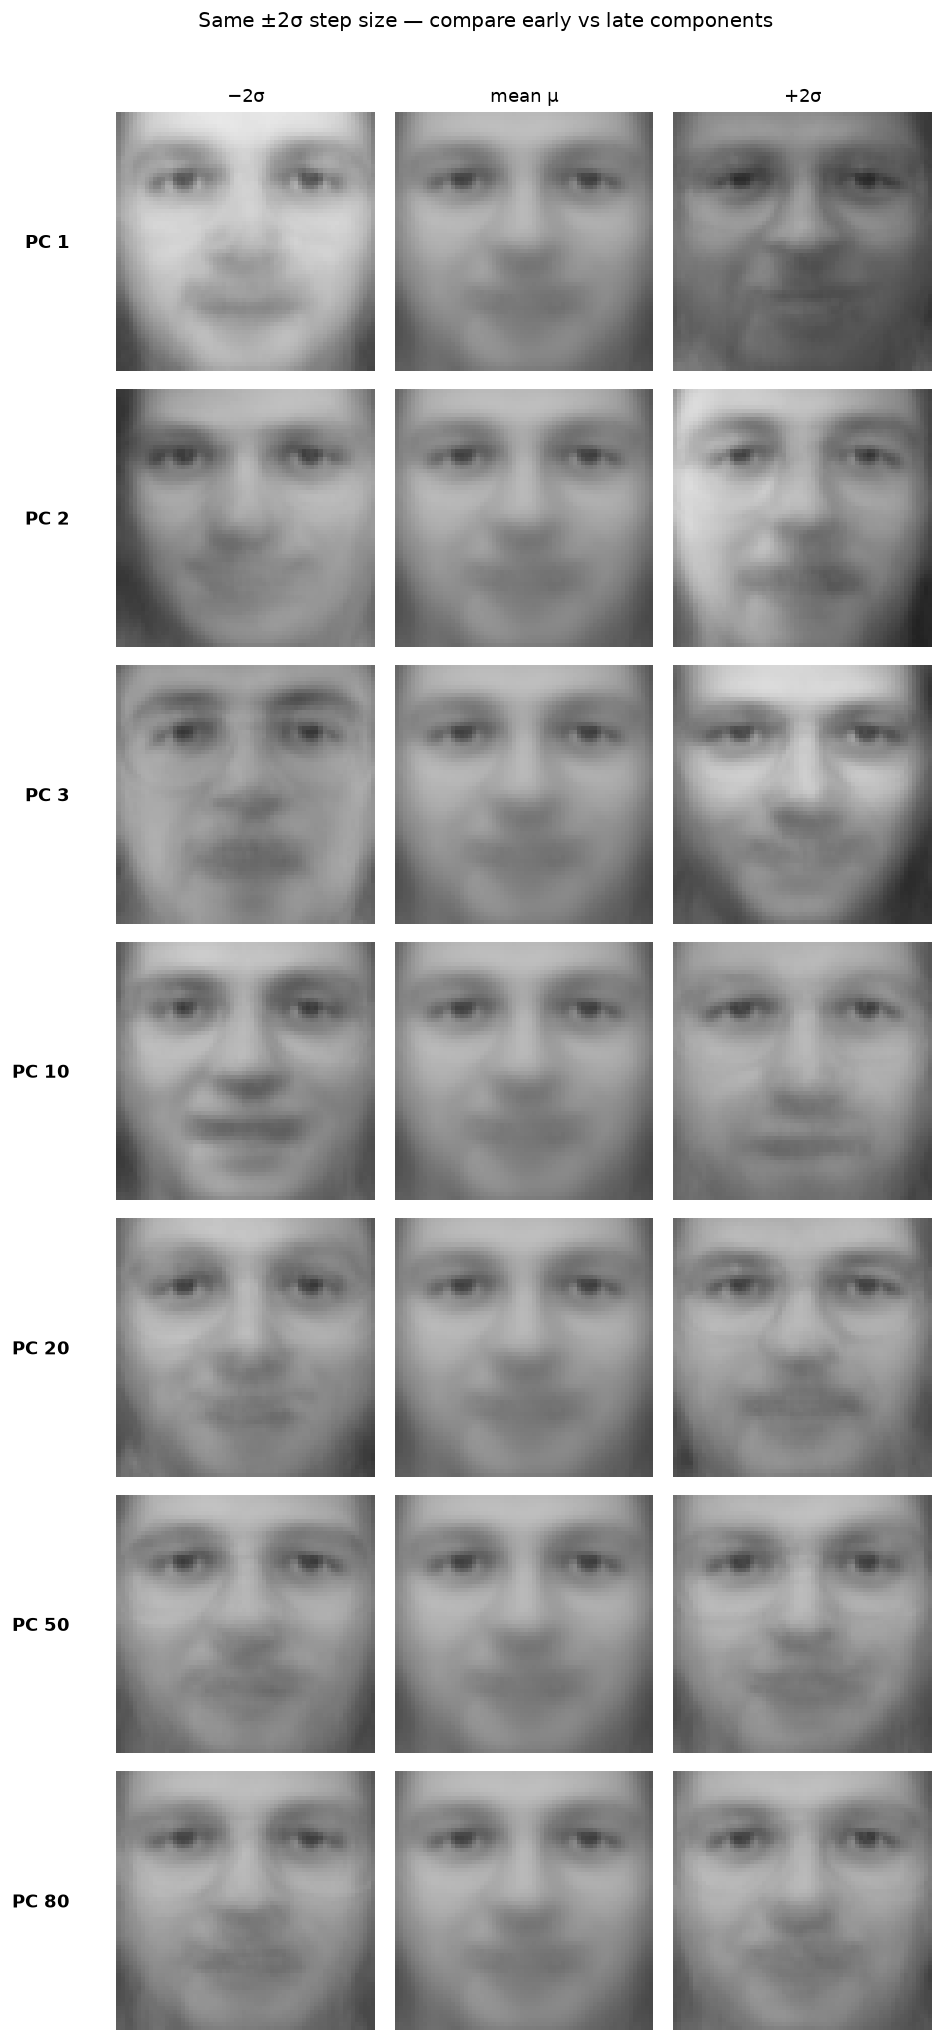

In [17]:
compare_pcs = [0, 1, 2, 9, 19, 49, 79]
fig, axes = plt.subplots(len(compare_pcs), 3, figsize=(8, 2.4 * len(compare_pcs)))
for row, pc in enumerate(compare_pcs):
    faces, _ = morph_strip(pc, multipliers=(-2, 0, 2))
    titles = [f"PC{pc+1} −2σ", "μ", f"PC{pc+1} +2σ"]
    for col in range(3):
        axes[row, col].imshow(faces[col].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(["−2σ", "mean μ", "+2σ"][col])
    axes[row, 0].text(-12, 32, f"PC {pc+1}", fontsize=11, fontweight="bold", ha="right", va="center")
plt.suptitle("Same ±2σ step size — compare early vs late components", y=1.01)
plt.tight_layout()
plt.show()

## 15. Measuring the coarse → fine shift

For many components we plot a few simple statistics:
- how “high-frequency” / speckled each eigenface is,
- how edge-like it looks,
- how strongly its scores still track overall brightness,
- how much total variation that component owns.

We are looking for a gradual handoff: early components smooth and brightness-heavy; later ones finer and less about the whole-image light level.


HF     early=0.0405  late=0.2076  Δ=+0.1672
Lap    early=0.0082  late=0.0204  Δ=+0.0121
|corr brightness| early=0.037 late=0.000
Later eigenfaces look more speckled / sharp on average — the coarse→fine shift shows up in the numbers.


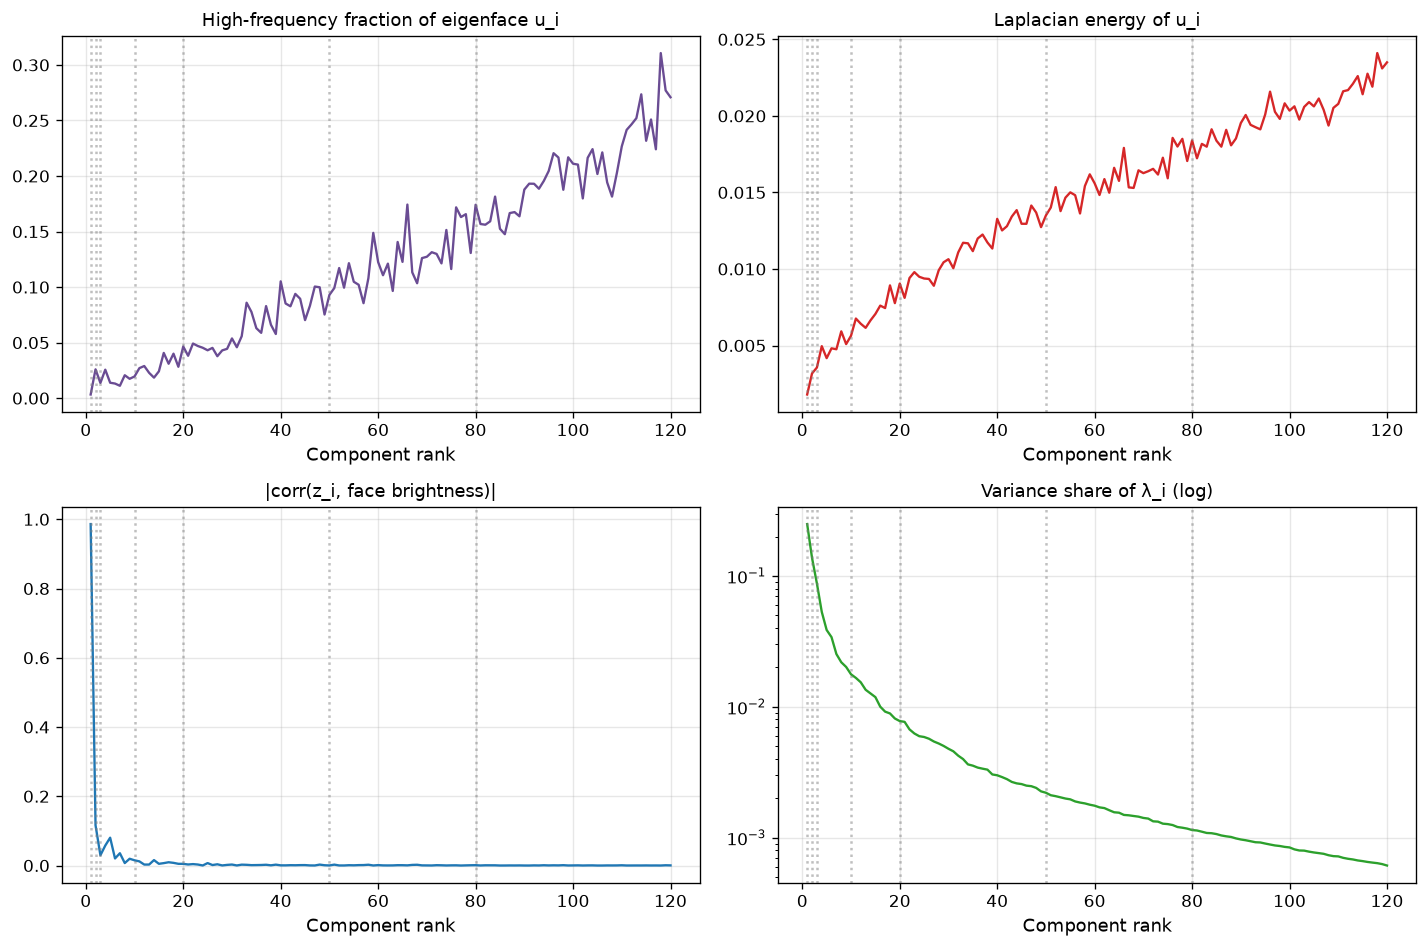

In [18]:
max_rank = min(120, eigenvectors.shape[1])
ranks = np.arange(1, max_rank + 1)
hf_scores = np.array([hf_fraction(eigenvectors[:, i]) for i in range(max_rank)])
lap_scores = np.array([laplacian_energy(eigenvectors[:, i]) for i in range(max_rank)])
bright_abs_corr = np.array([abs(corr(Z_all[:, i], bright)) for i in range(max_rank)])
var_share = eigenvalues[:max_rank] / eigenvalues[:max_rank].sum()

third = max_rank // 3
print(f"HF     early={hf_scores[:third].mean():.4f}  late={hf_scores[-third:].mean():.4f}  Δ={hf_scores[-third:].mean()-hf_scores[:third].mean():+.4f}")
print(f"Lap    early={lap_scores[:third].mean():.4f}  late={lap_scores[-third:].mean():.4f}  Δ={lap_scores[-third:].mean()-lap_scores[:third].mean():+.4f}")
print(f"|corr brightness| early={bright_abs_corr[:third].mean():.3f} late={bright_abs_corr[-third:].mean():.3f}")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(ranks, hf_scores, color="#6a4c93", lw=1.4)
axes[0, 0].set_title("High-frequency fraction of eigenface u_i")
axes[0, 1].plot(ranks, lap_scores, color="#d62728", lw=1.4)
axes[0, 1].set_title("Laplacian energy of u_i")
axes[1, 0].plot(ranks, bright_abs_corr, color="#1f77b4", lw=1.4)
axes[1, 0].set_title("|corr(z_i, face brightness)|")
axes[1, 1].semilogy(ranks, var_share, color="#2ca02c", lw=1.4)
axes[1, 1].set_title("Variance share of λ_i (log)")
for ax in axes.ravel():
    for r in [1, 2, 3, 10, 20, 50, 80]:
        if r <= max_rank:
            ax.axvline(r, color="gray", ls=":", alpha=0.5)
    ax.set_xlabel("Component rank")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

assert hf_scores[-third:].mean() > hf_scores[:third].mean()
print("Later eigenfaces look more speckled / sharp on average — the coarse→fine shift shows up in the numbers.")

## 16. Building a real face one piece at a time

For a real training face we rebuild it gradually:

$$
\hat{x}^{(i)}=\mu+\sum_{j=1}^{i} z_j u_j
$$

First the coarse head and shade arrive. Then the person sharpens. It is the same coarse-to-fine idea, but now on a real face instead of a synthetic morph.


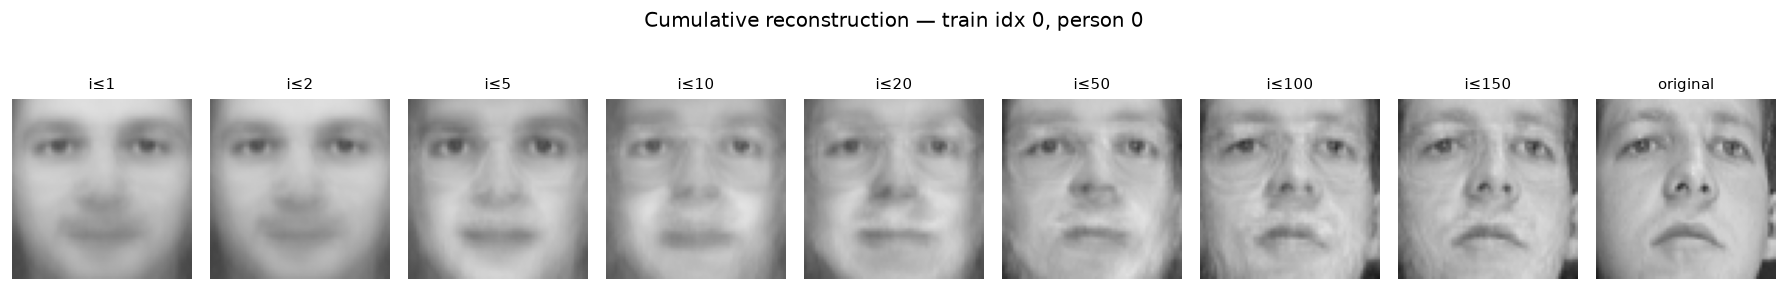

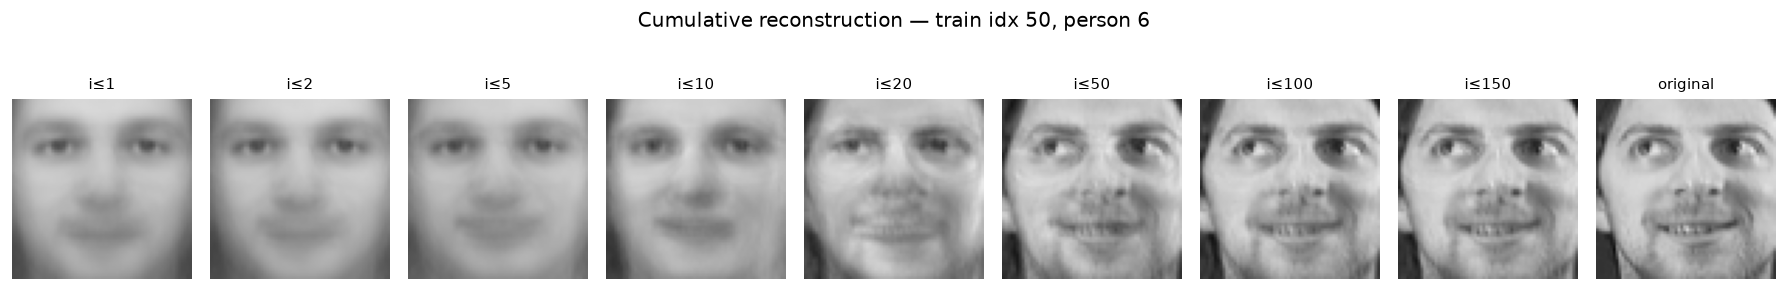

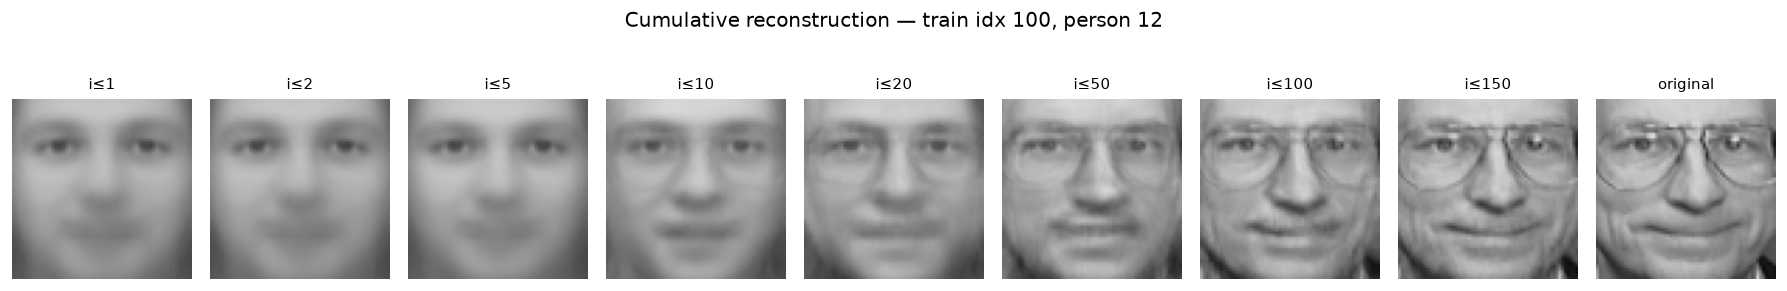

In [19]:
build_is = [1, 2, 5, 10, 20, 50, 100, 150]
example_idxs = [0, 50, 100]

for ti in example_idxs:
    x_c = X_train[ti]
    z = x_c @ eigenvectors
    imgs, titles = [], []
    for i in build_is:
        if i > eigenvectors.shape[1]:
            continue
        recon = mean_face + eigenvectors[:, :i] @ z[:i]
        imgs.append(np.clip(recon, 0, 1).reshape(64, 64))
        titles.append(f"i≤{i}")
    imgs.append(np.clip(x_c + mean_face, 0, 1).reshape(64, 64))
    titles.append("original")

    fig, axes = plt.subplots(1, len(imgs), figsize=(15, 2.4))
    for ax, img, title in zip(axes, imgs, titles):
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    plt.suptitle(f"Cumulative reconstruction — train idx {ti}, person {y_train[ti]}", y=1.05)
    plt.tight_layout()
    plt.show()

## 17. What if we rebuild **without** the first few components?

People often notice that the first components carry a lot of light and shade. So here we ask a simple what-if:

- rebuild a face using components **1 through 40**,
- rebuild the same face using components **4 through 43** (skip the first three),
- compare the error and, more importantly, the look.

Skipping early components usually makes the rebuild *worse* in numbers (those components hold a lot of variation). But the leftover face can look less globally re-lit. That tension is the point: early components are powerful for reconstruction, and they often spend that power on shade.


Centered MSE with PC1..40: 0.002439
Centered MSE with PC4..43: 0.012824
Skipping early components usually worsens pure reconstruction
(they hold lots of variation), but the leftover often looks less globally re-lit.


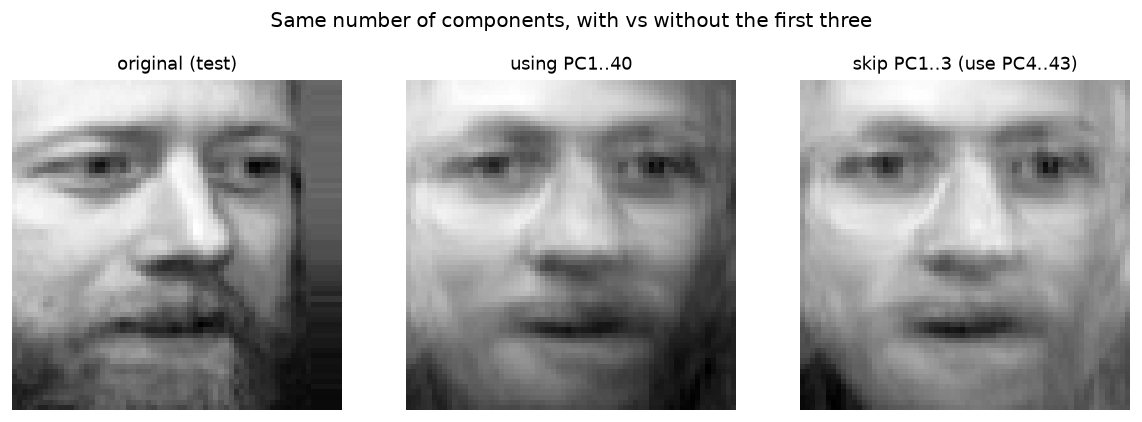

In [20]:
np.random.seed(42)
demo_idx = int(np.random.choice(len(X_test)))
x_c = X_test[demo_idx]
true_face = np.clip(x_c + mean_face, 0, 1).reshape(64, 64)

k_block = 40
U_full = eigenvectors[:, :k_block]
z_full = U_full.T @ x_c
recon_full = np.clip(mean_face + U_full @ z_full, 0, 1).reshape(64, 64)

U_skip = eigenvectors[:, 3:3 + k_block]
z_skip = U_skip.T @ x_c
recon_skip = np.clip(mean_face + U_skip @ z_skip, 0, 1).reshape(64, 64)

mse_full = float(np.mean((x_c - U_full @ z_full) ** 2))
mse_skip = float(np.mean((x_c - U_skip @ z_skip) ** 2))

print(f"Centered MSE with PC1..40: {mse_full:.6f}")
print(f"Centered MSE with PC4..43: {mse_skip:.6f}")
print("Skipping early components usually worsens pure reconstruction")
print("(they hold lots of variation), but the leftover often looks less globally re-lit.")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
axes[0].imshow(true_face, cmap="gray")
axes[0].set_title("original (test)")
axes[1].imshow(recon_full, cmap="gray")
axes[1].set_title("using PC1..40")
axes[2].imshow(recon_skip, cmap="gray")
axes[2].set_title("skip PC1..3 (use PC4..43)")
for ax in axes:
    ax.axis("off")
plt.suptitle("Same number of components, with vs without the first three", y=1.02)
plt.tight_layout()
plt.show()


## 18. How much does each component matter?

Most of the total variation sits in the first few components. That is why a face already looks “roughly right” with a small $k$, while later components spend their budget on leftovers — important for pixels, quieter for meaning.


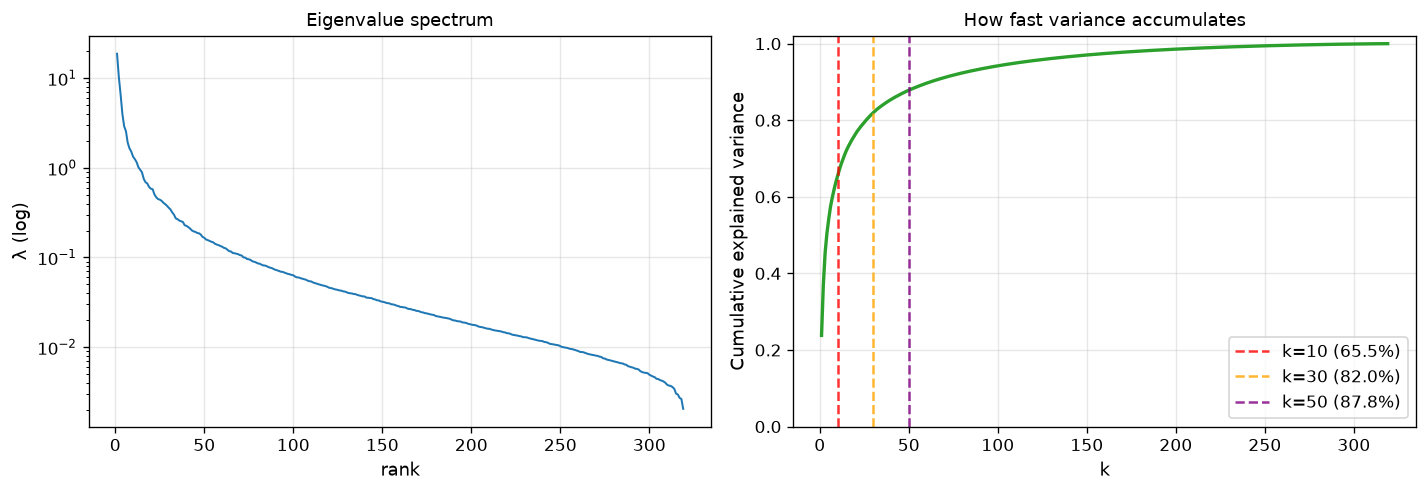

In [21]:
cum = np.cumsum(eigenvalues) / np.sum(eigenvalues)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].semilogy(np.arange(1, len(eigenvalues) + 1), eigenvalues, color="#1f77b4", lw=1.2)
axes[0].set_xlabel("rank"); axes[0].set_ylabel("λ (log)")
axes[0].set_title("Eigenvalue spectrum")
axes[0].grid(True, alpha=0.3)

axes[1].plot(np.arange(1, len(cum) + 1), cum, color="#2ca02c", lw=2)
for k, col in [(10, "red"), (30, "orange"), (50, "purple")]:
    axes[1].axvline(k, color=col, ls="--", alpha=0.8, label=f"k={k} ({100*cum[k-1]:.1f}%)")
axes[1].set_ylim(0, 1.02)
axes[1].set_xlabel("k")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_title("How fast variance accumulates")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Part III — What we conclude

After watching the morphs and checking the numbers, we land somewhere careful but clear:

**The early components mostly behave like light and large-scale shade.**  
PC1 tracks overall brightness almost perfectly. PC2 tracks left–right imbalance. PC3–PC4 lean vertical. When we move them, the whole face changes mood before it changes identity.

**The later components behave like fine leftover detail.**  
Same-sized steps do less and less to the global look. The eigenfaces themselves get more speckled. Brightness links fade. These components help rebuild the exact pixels of a person, but they resist clean English names — and that resistance is part of the answer.

**Skipping the first few components** makes reconstruction worse in MSE, which is expected: those directions hold a lot of variation. The interesting part is visual — the leftover can look less dominated by global shade.

**What we are willing to say out loud**
| Component | Plain reading |
|-----------|----------------|
| PC1 | overall light / dark |
| PC2 | left vs right shade |
| PC3–4 | more vertical shade / broad structure |
| mid ranks | structured local leftovers |
| late ranks | fine detail that rebuilds pixels, not a single concept |

**What we are *not* claiming**  
We are not saying PC1 is “pure lighting forever,” or that every dataset will order its components the same way. Olivetti is a calm dataset. PCA components are mixtures. Our readings are grounded in *this* split, these morphs, and these correlations.

**One practical lesson we liked**  
Using sample covariance $1/(n-1)$ made $\sqrt{\lambda}$ a real standard-deviation unit. The morphs stayed visually coherent. That small choice is what made the interpretation feel trustworthy instead of theatrical.


In [22]:
print("=" * 72)
print("SUMMARY — what we found")
print("=" * 72)
print(f"Retained components: {eigenvectors.shape[1]}")
print(f"Var(z)=λ check max rel err: {rel_err:.3e}")
print(f"HF early→late: {hf_scores[:third].mean():.4f} → {hf_scores[-third:].mean():.4f}")
print(f"Laplacian early→late: {lap_scores[:third].mean():.4f} → {lap_scores[-third:].mean():.4f}")
r1, r2, r3 = analysis_rows[0], analysis_rows[1], analysis_rows[2]
print(f"PC1 corr(z, brightness) = {r1['corr_brightness']:+.3f}  → overall shade")
print(f"PC2 corr(z, L-R asym)   = {r2['corr_LR']:+.3f}  → side lighting")
print(f"PC3 corr(z, T-B asym)   = {r3['corr_TB']:+.3f}  → vertical shading")
print("Later ranks: finer, more speckled, weaker brightness story.")
print("=" * 72)


SUMMARY — what we found
Retained components: 319
Var(z)=λ check max rel err: 2.011e-14
HF early→late: 0.0405 → 0.2076
Laplacian early→late: 0.0082 → 0.0204
PC1 corr(z, brightness) = -0.986  → overall shade
PC2 corr(z, L-R asym)   = +0.942  → side lighting
PC3 corr(z, T-B asym)   = +0.718  → vertical shading
Later ranks: finer, more speckled, weaker brightness story.


## Why the first eigenfaces are weak for **identification**

Reconstruction and identification want different things.

For reconstruction, early components are great: they hold most of the variation, so keeping them makes the rebuilt face look closer to the original.

For identification, we want directions that separate *people*. Overall light level is a bad clue for that. Two photos of the same person under different shade can sit far apart on PC1–PC3, while two different people under similar light can sit closer. So the first eigenfaces can help rebuild a face and still hurt matching.

**A standard reference for this idea.**  
Belhumeur, Hespanha & Kriegman (1997), *Eigenfaces vs. Fisherfaces*, IEEE TPAMI, argue that PCA keeps lighting and expression variation because it maximizes *total* scatter — good for rebuilding images, not always good for recognizing who is who. They also recall a sharp observation from Moses, Adini & Ullman: differences caused by lighting are often larger than differences caused by identity.

**Our short proof on this dataset.**  
We already saw that PC1 tracks brightness, PC2 tracks left–right shade, and PC3 tracks top–bottom shade. Below we turn that into an identification check: nearest-neighbor matching with the first $k$ components, versus the same number of components **after skipping PC1–PC3**. If early components were mostly identity, skipping them should hurt. If they are mostly shade, skipping them can help — or at least not hurt as much as their huge variance would suggest.


Identification check (nearest neighbor, Euclidean)
   k    use PC1..k  skip PC1-3, use next k   Δ (skip − keep)
  20        91.25%                  92.50%            +1.25%
  40        91.25%                  95.00%            +3.75%
  60        92.50%                  96.25%            +3.75%
  80        92.50%                  95.00%            +2.50%
 100        92.50%                  95.00%            +2.50%

Reminder from earlier measurements:
  PC1 corr with brightness     = -0.986
  PC2 corr with left–right     = +0.942
  PC3 corr with top–bottom     = +0.718
So the first three directions are strongly shade-like on our split.


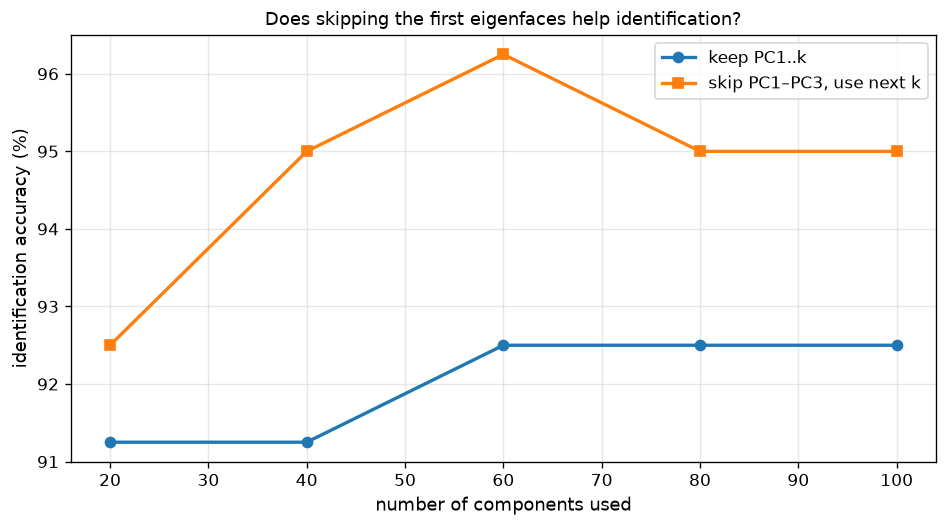

In [23]:
def nn_accuracy(U):
    """Nearest neighbor in Euclidean distance on projected scores."""
    train_w = X_train @ U
    test_w = X_test @ U
    correct = 0
    for i in range(len(test_w)):
        d = np.linalg.norm(train_w - test_w[i], axis=1)
        if y_train[np.argmin(d)] == y_test[i]:
            correct += 1
    return 100.0 * correct / len(y_test)

ks = [20, 40, 60, 80, 100]
acc_keep = []
acc_skip = []

print("Identification check (nearest neighbor, Euclidean)")
print(f"{'k':>4}  {'use PC1..k':>12}  {'skip PC1-3, use next k':>22}  {'Δ (skip − keep)':>16}")
for k in ks:
    U_keep = eigenvectors[:, :k]
    U_skip = eigenvectors[:, 3:3 + k]
    a_keep = nn_accuracy(U_keep)
    a_skip = nn_accuracy(U_skip)
    acc_keep.append(a_keep)
    acc_skip.append(a_skip)
    print(f"{k:>4}  {a_keep:>11.2f}%  {a_skip:>21.2f}%  {a_skip - a_keep:>+15.2f}%")

print("\nReminder from earlier measurements:")
print(f"  PC1 corr with brightness     = {analysis_rows[0]['corr_brightness']:+.3f}")
print(f"  PC2 corr with left–right     = {analysis_rows[1]['corr_LR']:+.3f}")
print(f"  PC3 corr with top–bottom     = {analysis_rows[2]['corr_TB']:+.3f}")
print("So the first three directions are strongly shade-like on our split.")

plt.figure(figsize=(8, 4.5))
plt.plot(ks, acc_keep, "o-", linewidth=2, label="keep PC1..k")
plt.plot(ks, acc_skip, "s-", linewidth=2, label="skip PC1–PC3, use next k")
plt.xlabel("number of components used")
plt.ylabel("identification accuracy (%)")
plt.title("Does skipping the first eigenfaces help identification?")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### A few quiet references

- Belhumeur, Hespanha & Kriegman (1997), *Eigenfaces vs. Fisherfaces* — why PCA’s first directions can be bad for identification when lighting dominates total variation.
- Background on eigenfaces more generally: Sirovich & Kirby (1987); Turk & Pentland (1991).

---

*We built the face space, checked that our step sizes were honest, changed one component at a time, and tried to say only what the faces themselves would let us say.*
